# Flight Delay Prediction: American Airlines

In this notebook we build a model that predicts whether an **American Airlines (AA)** domestic flight will be delayed.

We use data from the **Bureau of Transportation Statistics (BTS)**, the *Reporting Carrier On-Time Performance* dataset. It has one row per US domestic flight, and we use all of 2025 (January–December).

## 1. Introduction

### Business question
> *"Can American Airlines' operations team use ML to predict flight delays (>15 min) before departure for proactive resource allocation?"*

Delays are expensive. A study funded by the FAA (Ball et al., 2010) estimated that flight delays cost the US economy **about $33 billion a year**. The costs land on airlines (crew, fuel, maintenance), on passengers (lost time) and on the wider economy.

If the operations team knows a flight is likely to be delayed, they can act before it happens. For example, they can have a spare aircraft or crew ready, move gate staff, or rebook passengers with tight connections.

### ML question
> *"Can we predict whether an American Airlines flight will arrive more than 15 minutes late, using only information available 2 hours before departure?"*

This is a **binary classification** problem:

- Each row is one scheduled AA flight.
- The target is `Delayed`. It is `1` if the flight arrives more than 15 minutes late (the official US Department of Transportation definition) and `0` otherwise.
- We make the prediction **2 hours before departure**. So we can only use what is known at that point: the schedule (date, time, route, distance), which aircraft is assigned (`Tail_Number`) and historical patterns. Anything we only learn at or after departure is off limits.

### Imports
All libraries are imported here in one place.

In [35]:
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import requests
import seaborn as sns
from fairlearn.metrics import (
    MetricFrame,
    false_positive_rate,
    selection_rate,
    true_positive_rate,
)
from fairlearn.postprocessing import ThresholdOptimizer
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from xgboost import XGBClassifier

# Consistent colour palette for all plots
COLOR_DELAYED = "#eb6834"  # orange: delayed
COLOR_ONTIME = "#2a78d6"   # blue: on time
COLOR_REF = "#8a8984"      # grey: reference line

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#d6d5d0",
    "grid.color": "#ecebe7",
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
})

RANDOM_STATE = 42

## 2. Data Loading & Cleaning

### 2.1 Download the raw data

BTS publishes one zip file per month. The cell below goes through all 12 months of 2025 and:

1. Downloads the zip file to `data/`, unless we already have it.
2. Reads the CSV file inside it with **all** of its columns (more than 100).
3. Keeps only the columns we need.

We do the column selection month by month. Loading all columns for 7 million flights at once would not fit in memory on a normal laptop.

These are the columns we keep:

| Column | Why we keep it |
|---|---|
| `FlightDate`, `Month`, `DayOfWeek`, `CRSDepTime`, `CRSArrTime` | When the flight is scheduled to depart and arrive. Known in advance |
| `Origin`, `Dest`, `Distance` | The route. Known in advance |
| `Tail_Number` | Which aircraft flies it. Known 2 hours before departure |
| `Reporting_Airline` | So we can filter to AA |
| `Cancelled`, `Diverted` | So we can remove flights that never arrived |
| `ArrDelay` | To build the target |
| `CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay` | Reasons for the delay. Used **only for exploration**, never as features |

In [36]:
YEAR = 2025
MONTHS = range(1, 13)
URL_TEMPLATE = (
    "https://transtats.bts.gov/PREZIP/"
    "On_Time_Reporting_Carrier_On_Time_Performance_1987_present_{year}_{month}.zip"
)

DELAY_CAUSES = ["CarrierDelay", "WeatherDelay", "NASDelay", "LateAircraftDelay", "SecurityDelay"]
COLUMNS = [
    "FlightDate", "Month", "DayOfWeek", "Origin", "Dest", "CRSDepTime", "CRSArrTime",
    "ArrDelay", "Cancelled", "Diverted", "Distance", "Tail_Number",
    *DELAY_CAUSES, "Reporting_Airline",
]

DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

monthly_frames = []

for month in MONTHS:
    url = URL_TEMPLATE.format(year=YEAR, month=month)
    zip_path = DATA_DIR / f"ontime_{YEAR}_{month:02d}.zip"

    # 1) Download (only if we don't already have the file)
    if not zip_path.exists():
        print(f"Downloading {url} ...")
        with requests.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(zip_path, "wb") as f:
                for chunk in r.iter_content(chunk_size=1 << 20):
                    f.write(chunk)

    # 2) Read the CSV file directly from the zip, with all columns
    with zipfile.ZipFile(zip_path) as zf:
        csv_name = next(n for n in zf.namelist() if n.lower().endswith(".csv"))
        with zf.open(csv_name) as f:
            df_month = pd.read_csv(f, low_memory=False)

    print(f"{YEAR}-{month:02d}: {len(df_month):,} rows, {df_month.shape[1]} columns available")

    # 3) Keep only the columns we need
    monthly_frames.append(df_month[COLUMNS])

# 4) Combine all months into one DataFrame
raw = pd.concat(monthly_frames, ignore_index=True)
print(f"\nTotal: {len(raw):,} flights (all airlines), {raw.shape[1]} columns selected")

2025-01: 539,747 rows, 110 columns available
2025-02: 504,884 rows, 110 columns available
2025-03: 600,872 rows, 110 columns available
2025-04: 583,950 rows, 110 columns available
2025-05: 605,648 rows, 110 columns available
2025-06: 611,575 rows, 110 columns available
2025-07: 631,428 rows, 110 columns available
2025-08: 602,378 rows, 110 columns available
2025-09: 562,439 rows, 110 columns available
2025-10: 605,844 rows, 110 columns available
2025-11: 570,550 rows, 110 columns available
2025-12: 582,304 rows, 110 columns available

Total: 7,001,619 flights (all airlines), 18 columns selected


### 2.2 Keep only American Airlines

The dataset covers every US airline. We keep only AA's flights. After that, every row has the same airline, so we drop the `Reporting_Airline` column.

In [37]:
df = raw[raw["Reporting_Airline"] == "AA"].drop(columns=["Reporting_Airline"])

print(f"AA flights: {len(df):,} of {len(raw):,} ({len(df) / len(raw):.1%})")

AA flights: 973,653 of 7,001,619 (13.9%)


### 2.3 Remove cancelled and diverted flights

A cancelled flight never takes off, and a diverted flight lands somewhere else. Neither has a real arrival delay, so we can't say whether they were "late". We remove them.

After that, the `Cancelled` and `Diverted` columns only contain 0, so we drop them too.

In [38]:
n_before = len(df)

df = df[(df["Cancelled"] != 1) & (df["Diverted"] != 1)]
df = df.drop(columns=["Cancelled", "Diverted"])

print(f"Removed {n_before - len(df):,} cancelled/diverted flights")
print(f"Remaining: {len(df):,} rows")

Removed 20,812 cancelled/diverted flights
Remaining: 952,841 rows


### 2.4 Remove rows with no arrival delay

We build the target from `ArrDelay`. If it is missing, we can't tell whether the flight was late, so we drop the row.

In [39]:
n_before = len(df)

df = df.dropna(subset=["ArrDelay"]).reset_index(drop=True)

print(f"Removed {n_before - len(df):,} rows with missing ArrDelay")
print(f"Remaining: {len(df):,} rows")

Removed 0 rows with missing ArrDelay
Remaining: 952,841 rows


### 2.5 Create the target: `Delayed`

We use the official definition: a flight is delayed if it arrives **more than 15 minutes** after its scheduled time.

- `Delayed = 1`: delayed (`ArrDelay > 15`)
- `Delayed = 0`: on time

In [40]:
df["Delayed"] = (df["ArrDelay"] > 15).astype(int)

### 2.6 Avoid cheating: target leakage

Our model has to predict 2 hours before departure. So it may only use information we actually have at that point. If it uses information from the future, it will look great in testing and fail in practice. This is called **target leakage**. Kapoor & Narayanan (2023) show it is one of the most common mistakes in machine learning projects.

Two groups of columns would leak the answer:

- **`ArrDelay` is the answer itself.** If we know how late a flight arrived, we already know whether it was delayed.
- **The delay cause columns** (`CarrierDelay`, `WeatherDelay`, `NASDelay`, `LateAircraftDelay`, `SecurityDelay`) are only filled in after the flight lands, and only when it was delayed. Using them would be cheating.

The delay causes are still useful for *understanding* delays, for example how many are caused by a late incoming aircraft. So we move them, together with `ArrDelay`, into a separate DataFrame called `delay_causes` for the exploration later. Then we remove them from the main dataset, so they can't end up as features by accident.

In [41]:
# Separate DataFrame for EDA: same index as df, so they can be joined again
delay_causes = df[["ArrDelay", *DELAY_CAUSES]].copy()

# Remove the leakage columns from the main dataset
df = df.drop(columns=["ArrDelay", *DELAY_CAUSES])

print("delay_causes:", delay_causes.shape)
print("df:          ", df.shape)
print("Columns in df:", list(df.columns))

delay_causes: (952841, 6)
df:           (952841, 10)
Columns in df: ['FlightDate', 'Month', 'DayOfWeek', 'Origin', 'Dest', 'CRSDepTime', 'CRSArrTime', 'Distance', 'Tail_Number', 'Delayed']


### 2.7 Strengths and limitations of the data

What the data does well:
- It contains every AA domestic flight in 2025, not a sample.
- It is an official source with the same definitions everywhere.
- A full year covers all seasons: winter storms, summer peaks and holidays.
- About 950,000 flights is plenty for training and testing.
- `Tail_Number` lets us follow each aircraft through its day.

What it can't tell us:
- There is no weather data, even though weather causes many delays.
- It only covers one year, so we can't check whether patterns hold in 2026.
- Removing cancelled flights hides the worst days, because cancellations cluster on bad days.
- International flights are not included.
- There is no operational data, such as passenger numbers, staffing or maintenance.
- It is observational data. We can find patterns, but not prove what causes delays.

### 2.8 Class balance

How many flights are delayed compared with on time?

This matters because accuracy can be misleading when the classes are uneven. A model that always says "on time" would be right most of the time and still be useless. We will handle this later with class weights and metrics such as ROC-AUC and PR-AUC.

              Count  Share
On time (0)  714611  75.0%
Delayed (1)  238230  25.0%


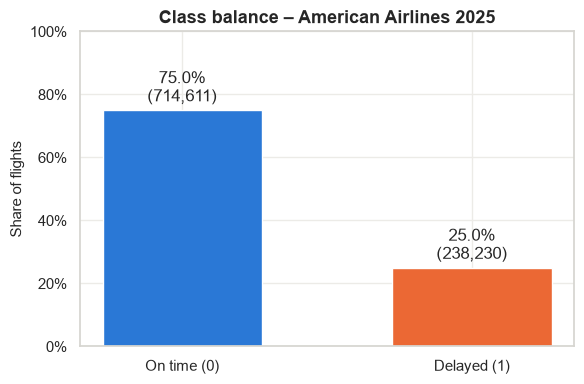

In [42]:
counts = df["Delayed"].value_counts().sort_index()
shares = counts / counts.sum()

balance = pd.DataFrame({"Count": counts, "Share": shares.map("{:.1%}".format)})
balance.index = ["On time (0)", "Delayed (1)"]
print(balance)

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(balance.index, shares.values, color=[COLOR_ONTIME, COLOR_DELAYED], width=0.55)
ax.bar_label(bars, labels=[f"{s:.1%}\n({c:,})" for s, c in zip(shares, counts)], padding=3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, 1)
ax.set_ylabel("Share of flights")
ax.set_title("Class balance – American Airlines 2025")
plt.tight_layout()
plt.show()

### 2.9 Save the cleaned datasets

We save two files, so the next sections can start from here without downloading and cleaning everything again:

- `cleaned_flights_aa.csv`: the main dataset we model on.
- `delay_causes_aa.csv`: `ArrDelay` and the delay causes, for exploration only. It has the same rows in the same order as the main dataset.

In [43]:
df.to_csv("cleaned_flights_aa.csv", index=False)
delay_causes.to_csv("delay_causes_aa.csv", index=False)

print(f"Saved cleaned_flights_aa.csv ({len(df):,} rows, {df.shape[1]} columns)")
print(f"Saved delay_causes_aa.csv ({len(delay_causes):,} rows, {delay_causes.shape[1]} columns)")
display(df.head())

Saved cleaned_flights_aa.csv (952,841 rows, 10 columns)
Saved delay_causes_aa.csv (952,841 rows, 6 columns)


,FlightDate,Month,DayOfWeek,Origin,Dest,CRSDepTime,CRSArrTime,Distance,Tail_Number,Delayed
0,2025-01-01,1,3,JFK,LAX,659,1020,2475.0,N104NN,0
1,2025-01-02,1,4,JFK,LAX,659,1020,2475.0,N110AN,0
2,2025-01-03,1,5,JFK,LAX,659,1020,2475.0,N106NN,0
3,2025-01-04,1,6,JFK,LAX,700,1026,2475.0,N117AN,0
4,2025-01-05,1,7,JFK,LAX,659,1020,2475.0,N104NN,0


## 3. Exploratory Data Analysis

Before we build any models, we look at when and where AA's flights get delayed. This tells us which features are likely to be useful and what patterns the model should be able to pick up. Each plot below shows the **delay rate**: the share of flights that arrived more than 15 minutes late.

### 3.1 Load the data

We load the cleaned dataset and add one feature: `DepHour`, the scheduled departure hour.

`CRSDepTime` is stored as `hhmm` (e.g. `1435` = 14:35), so dividing by 100 and dropping the remainder gives the hour (14).

In [44]:
df = pd.read_csv("cleaned_flights_aa.csv")
df["DepHour"] = df["CRSDepTime"] // 100

OVERALL_RATE = df["Delayed"].mean()
print(f"Loaded {len(df):,} flights. Overall delay rate: {OVERALL_RATE:.1%}")


def add_reference(ax):
    """Draw the overall delay rate as a dashed reference line."""
    ax.axhline(OVERALL_RATE, color=COLOR_REF, linestyle="--", linewidth=1.2,
               label=f"Overall average ({OVERALL_RATE:.1%})")
    ax.legend(frameon=False, loc="upper left")

Loaded 952,841 flights. Overall delay rate: 25.0%


### 3.2 Delay rate by departure hour

Does the time of day matter? If delays build up as aircraft fly several legs a day, later flights should be delayed more often.

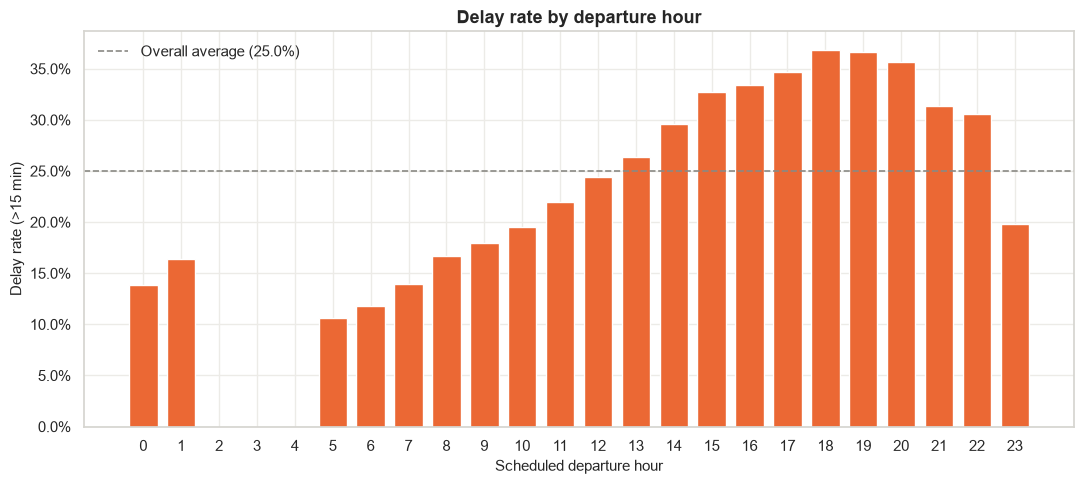

In [45]:
rate_hour = df.groupby("DepHour")["Delayed"].mean()

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(rate_hour.index, rate_hour.values, color=COLOR_DELAYED, width=0.75)
add_reference(ax)

ax.set_xticks(range(24))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Scheduled departure hour")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate by departure hour")
plt.tight_layout()
plt.show()

**What we see:** The delay rate climbs steadily through the day. It goes from about 11% for 5 am departures to about 37% around 6–7 pm, before dropping late at night. There are almost no departures between 2 and 4 am, and very few around midnight.

**Why it matters:** This is the **cascade effect**. An aircraft flies several legs a day, and a delay on an early leg carries over to the next ones. `DepHour` will probably be one of the strongest features.

### 3.3 Delay rate by month

Are some times of year worse than others?

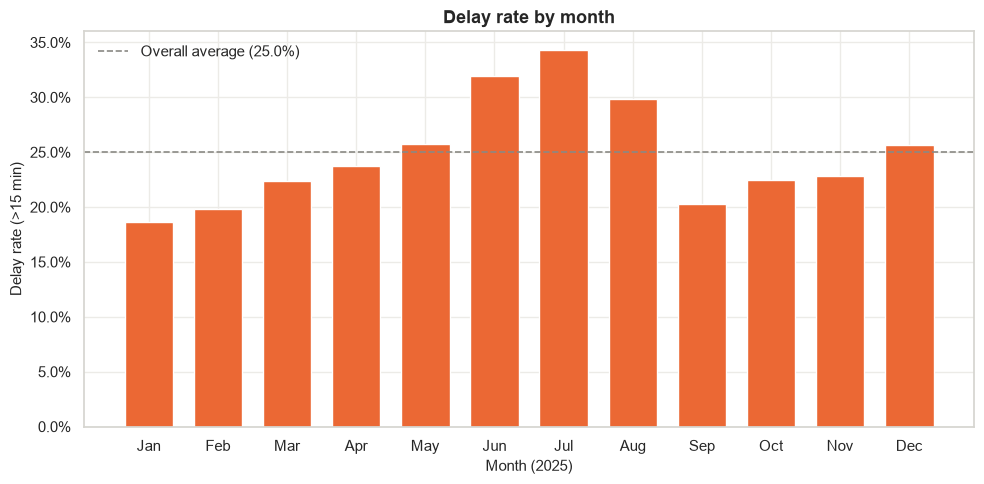

In [46]:
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
               "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

rate_month = df.groupby("Month")["Delayed"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(MONTH_NAMES, rate_month.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax)

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Month (2025)")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate by month")
plt.tight_layout()
plt.show()

**What we see:** There is a clear **summer peak**. June and July are the worst months (32% and 34%), when traffic is high and thunderstorms are common. **December** is also above average (26%) because of holiday traffic and winter weather. January and February are the calmest months (19–20%).

**Why it matters:** `Month` captures seasonal patterns, so it should help the model. The effect is smaller than for departure hour, though.

### 3.4 Delay rate by day of week and distance

Two more features to check:

- **Day of week:** does traffic on certain days, such as busy weekend travel, lead to more delays?
- **Distance:** are long flights delayed more often than short ones? We group flights into 500-mile bins.

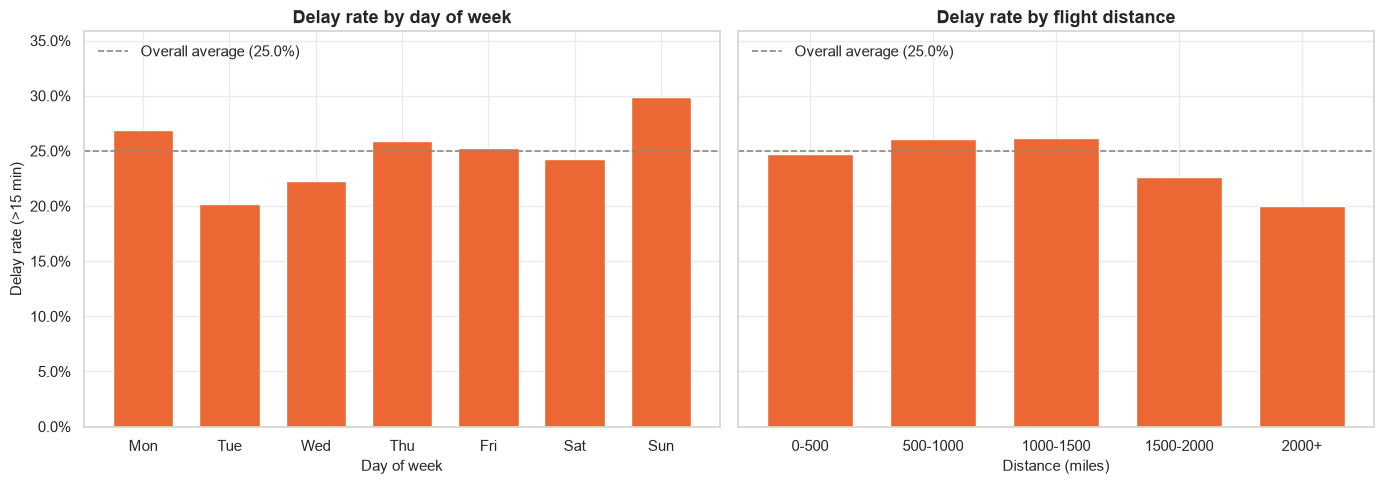

In [47]:
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
DISTANCE_BINS = [0, 500, 1000, 1500, 2000, np.inf]
DISTANCE_LABELS = ["0-500", "500-1000", "1000-1500", "1500-2000", "2000+"]

rate_weekday = df.groupby("DayOfWeek")["Delayed"].mean()
distance_bin = pd.cut(df["Distance"], bins=DISTANCE_BINS, labels=DISTANCE_LABELS, right=False)
rate_distance = df.groupby(distance_bin, observed=True)["Delayed"].mean()

fig, (ax_day, ax_dist) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

ax_day.bar(WEEKDAYS, rate_weekday.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax_day)
ax_day.set_xlabel("Day of week")
ax_day.set_ylabel("Delay rate (>15 min)")
ax_day.set_title("Delay rate by day of week")

ax_dist.bar(DISTANCE_LABELS, rate_distance.values, color=COLOR_DELAYED, width=0.7)
add_reference(ax_dist)
ax_dist.set_xlabel("Distance (miles)")
ax_dist.set_title("Delay rate by flight distance")

ax_day.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax_day.set_ylim(0, max(rate_weekday.max(), rate_distance.max()) * 1.2)
plt.tight_layout()
plt.show()

**What we see:** **Sunday** has the highest delay rate (30%), followed by Monday (27%). These are the busiest return-travel days after the weekend. Tuesday is the calmest day (20%). Saturday (24%) is actually slightly below average, so the effect is about Sunday and Monday rather than the weekend as a whole.

Distance makes little difference for most flights: everything up to 1,500 miles sits at 25–26%. Only the longest flights are delayed less often (23% for 1,500–2,000 miles and 20% for 2,000+). A likely reason is that long flights have more room in the schedule to make up lost time in the air.

**Why it matters:** `DayOfWeek` has a clear effect of about 10 percentage points between the best and worst day, so it is worth keeping. `Distance` is a weak feature on its own, but may still help in combination with route and airport.

### 3.5 Delay rate at AA's 10 busiest airports

AA runs a hub-and-spoke network: many flights go through a few large hubs. Are the hubs more delay-prone than other busy airports?

The five hubs (DFW, CLT, MIA, ORD, PHX) are shown in solid colour with bold labels. The other busy airports are shown in a lighter shade.

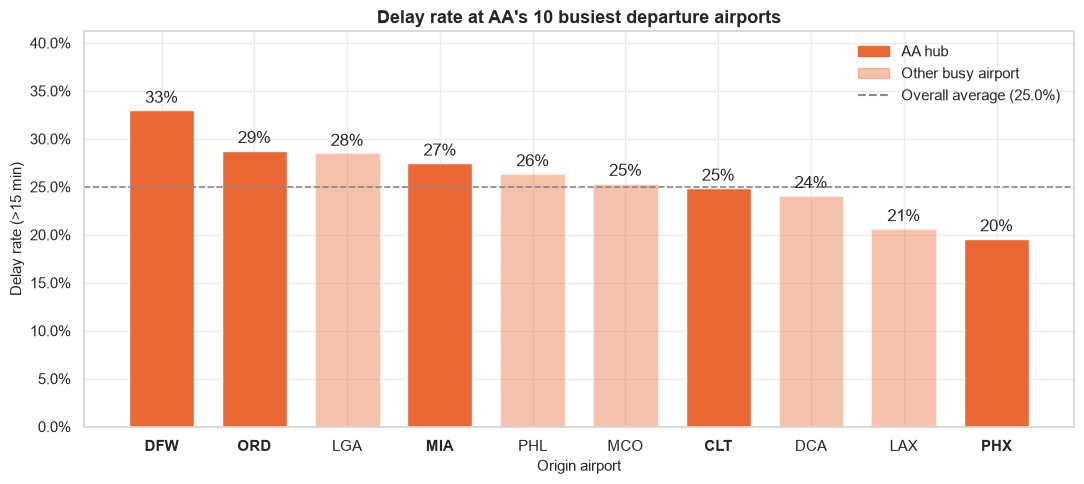

In [48]:
HUBS = ["DFW", "CLT", "MIA", "ORD", "PHX"]

top10 = df["Origin"].value_counts().head(10).index
rate_airport = (
    df[df["Origin"].isin(top10)]
    .groupby("Origin")["Delayed"].mean()
    .sort_values(ascending=False)
)
is_hub = rate_airport.index.isin(HUBS)

fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(rate_airport.index, rate_airport.values, color=COLOR_DELAYED, width=0.7)
for bar, hub in zip(bars, is_hub):
    bar.set_alpha(1.0 if hub else 0.4)
ax.bar_label(bars, labels=[f"{r:.0%}" for r in rate_airport.values], padding=3)

for label, hub in zip(ax.get_xticklabels(), is_hub):
    label.set_fontweight("bold" if hub else "normal")

ax.axhline(OVERALL_RATE, color=COLOR_REF, linestyle="--", linewidth=1.2)
ax.legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color=COLOR_DELAYED, alpha=1.0, label="AA hub"),
        plt.Rectangle((0, 0), 1, 1, color=COLOR_DELAYED, alpha=0.4, label="Other busy airport"),
        plt.Line2D([], [], color=COLOR_REF, linestyle="--", label=f"Overall average ({OVERALL_RATE:.1%})"),
    ],
    frameon=False, loc="upper right",
)

ax.set_ylim(0, rate_airport.max() * 1.25)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Origin airport")
ax.set_ylabel("Delay rate (>15 min)")
ax.set_title("Delay rate at AA's 10 busiest departure airports")
plt.tight_layout()
plt.show()

**What we see:** Being a hub does not automatically mean more delays. **DFW**, AA's biggest hub, has the highest delay rate (33%), and ORD and MIA are also above average. But **CLT** (25%) is right at the average, and **PHX** (20%) has the lowest rate of the ten. Congested non-hub airports like LGA and PHL are also well above average.

**Why it matters:** Delay rates differ a lot between airports (20% to 33% among just these ten). So `Origin`, and probably `Dest`, carry useful information. A simple hub/non-hub flag would miss most of it, because the hubs themselves differ so much.

### 3.6 What causes the delays?

For every delayed flight, the airline reports how many minutes were caused by each of five reasons:

- **LateAircraftDelay:** the incoming aircraft arrived late (the cascade effect)
- **CarrierDelay:** the airline's own fault, e.g. crew, maintenance, baggage or fuelling
- **NASDelay:** the air traffic system, e.g. congestion or air traffic control
- **WeatherDelay:** extreme weather
- **SecurityDelay:** security problems, e.g. evacuations or long screening queues

For each delayed flight, we compute each cause's share of the total delay, then average those shares across all delayed flights.

**Note:** As explained in section 2.6, these columns are **not** used as features. They are only filled in after the flight lands, so using them would leak the answer. We use them here only to understand what drives delays.

Delayed flights: 238,230
Late aircraft (cascade)     41.2%
Carrier                     29.4%
Air traffic system (NAS)    25.2%
Weather                      4.0%
Security                     0.2%


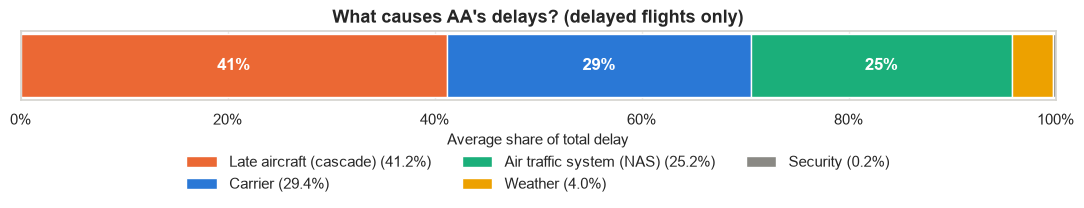

In [49]:
delay_causes = pd.read_csv("delay_causes_aa.csv")

CAUSE_LABELS = {
    "LateAircraftDelay": "Late aircraft (cascade)",
    "CarrierDelay": "Carrier",
    "NASDelay": "Air traffic system (NAS)",
    "WeatherDelay": "Weather",
    "SecurityDelay": "Security",
}
CAUSE_COLORS = [COLOR_DELAYED, COLOR_ONTIME, "#1baf7a", "#eda100", COLOR_REF]
causes = list(CAUSE_LABELS)

# Only delayed flights, where the causes are filled in
delayed = delay_causes[delay_causes["ArrDelay"] > 15]
total_minutes = delayed[causes].sum(axis=1)

# Each cause's share of the flight's total delay, averaged over all delayed flights
cause_share = (
    delayed[causes]
    .div(total_minutes, axis=0)[total_minutes > 0]
    .mean()
)
print(f"Delayed flights: {len(delayed):,}")
print(cause_share.rename(CAUSE_LABELS).map("{:.1%}".format).to_string())

fig, ax = plt.subplots(figsize=(11, 3.4))
left = 0
for cause, color in zip(causes, CAUSE_COLORS):
    share = cause_share[cause]
    ax.barh(0, share, left=left, color=color, label=f"{CAUSE_LABELS[cause]} ({share:.1%})")
    if share > 0.05:
        ax.text(left + share / 2, 0, f"{share:.0%}", ha="center", va="center",
                color="white", fontweight="bold", fontsize=12)
    left += share

ax.set_xlim(0, 1)
ax.set_yticks([])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Average share of total delay")
ax.set_title("What causes AA's delays? (delayed flights only)")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.6), ncol=3)
plt.tight_layout()
plt.show()

**What we see:** **Late aircraft** is the biggest cause, at about 41% of the average delay. The airline's own issues (carrier, about 29%) and the air traffic system (NAS, about 25%) come next. Extreme weather (about 4%) and security (under 1%) play a small part. Bad weather often shows up as NAS delays instead, because it slows down air traffic control.

**Why it matters:** The cascade effect is the single largest driver of delays. It also explains the departure-hour pattern in 3.2: the later in the day, the more earlier legs there are for a delay to build up on. Features that track an aircraft's previous legs (via `Tail_Number`) could therefore be valuable, as long as they only use information known 2 hours before departure.

### 3.7 Correlation matrix

Finally, we check the linear correlation between the numerical features and the target. A value near 0 means no linear relationship. Values near ±1 mean a strong one.

Two things to look for:
- **Feature vs. `Delayed`:** which features move together with delays?
- **Feature vs. feature:** are any features so strongly related that they carry the same information?

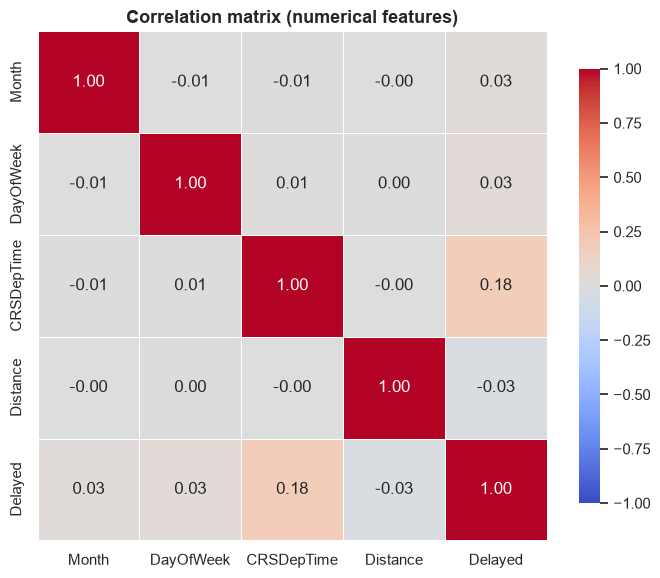

In [50]:
corr = df[["Month", "DayOfWeek", "CRSDepTime", "Distance", "Delayed"]].corr()

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Correlation matrix (numerical features)")
plt.tight_layout()
plt.show()

**What we see:** All correlations are weak. `CRSDepTime` has the strongest link to `Delayed` (0.18), which fits the departure-hour pattern. `Month`, `DayOfWeek` and `Distance` are close to 0. The features are also unrelated to each other, so there is no redundancy.

**Why it matters:** Correlation only measures *straight-line* relationships. The month effect goes up in summer and back down in autumn, so it has a near-zero correlation even though 3.3 showed a clear pattern. This is a reason to use models that can capture non-linear patterns, such as decision trees, random forests and XGBoost.

### 3.8 EDA summary

| Feature | Strength | Why |
|---|---|---|
| `DepHour` / `CRSDepTime` | Strong | Delay rate rises from 11% to 37% through the day (cascade effect) |
| `Origin` / `Dest` | Strong | Delay rates range from 20% to 33% among the 10 busiest airports alone |
| `Month` | Moderate | Clear summer peak (34% in July vs. 19% in January), but non-linear |
| `DayOfWeek` | Moderate | Ranges from 20% (Tuesday) to 30% (Sunday) |
| `Distance` | Weak | Flat at 25–26% up to 1,500 miles; only the longest flights are less delayed (20%) |
| Delay causes | Not a feature | Leakage, but show that late incoming aircraft are the biggest driver |

## 4. Feature Engineering & Train/Test Split

Now we turn the cleaned data into the features the models will use. The rule from the ML question still applies: every feature must be **known 2 hours before departure**. That means we can only use the schedule, the route and historical patterns, never anything about how the flight actually went.

### 4.1 Basic features

In [51]:
HUBS = ["DFW", "CLT", "MIA", "ORD", "PHX"]

df = pd.read_csv("cleaned_flights_aa.csv")

# Scheduled departure hour: 1435 -> 14
df["DepHour"] = df["CRSDepTime"] // 100
df = df.drop(columns=["CRSDepTime"])

# Saturday (6) or Sunday (7)
df["IsWeekend"] = df["DayOfWeek"].isin([6, 7]).astype(int)

# Departure from one of AA's five hubs
df["IsHub"] = df["Origin"].isin(HUBS).astype(int)

# FlightDate is dropped: Month and DayOfWeek already hold the useful parts
df = df.drop(columns=["FlightDate"])
df = df[["Month", "DayOfWeek", "DepHour", "IsWeekend", "IsHub", "Distance",
         "Origin", "Dest", "Tail_Number", "Delayed"]]

print("Shape:", df.shape)
print("Columns:", list(df.columns))

Shape: (952841, 10)
Columns: ['Month', 'DayOfWeek', 'DepHour', 'IsWeekend', 'IsHub', 'Distance', 'Origin', 'Dest', 'Tail_Number', 'Delayed']


All of these come straight from the published schedule, so they are known long before the flight:

- **`Month`, `DayOfWeek`:** when the flight is scheduled. Captures the seasonal and weekly patterns from the EDA.
- **`DepHour`:** scheduled departure hour. The strongest pattern in the EDA (the cascade effect).
- **`IsWeekend`:** 1 for Saturday and Sunday. Makes it easy for a model to pick up a weekend effect.
- **`IsHub`:** 1 if the flight departs from DFW, CLT, MIA, ORD or PHX. Hub operations are busier and more complex.
- **`Distance`:** route length in miles. Fixed for each route.
- **`Origin`, `Dest`:** the airports. Still text, so they are encoded in 4.3.
- **`Tail_Number`:** the assigned aircraft, which is known at T-2 hours. We keep it for now and decide in 4.3.

### 4.1b Previous-leg delay

Section 3.6 showed that **late aircraft** is the biggest cause of delays (41%): if an aircraft's previous flight arrived late, its next flight often leaves late too. `Tail_Number` lets us follow each aircraft through its day, so we can turn this cascade effect into a feature.

For each flight we look at the **same aircraft's previous flight on the same day**:

- **`PrevLegDelay`:** how many minutes late the previous leg arrived (`ArrDelay`, negative if early), or 0 if there is no qualifying previous leg.
- **`HasPrevLeg`:** 1 if there is a qualifying previous leg, 0 otherwise. We need it because `PrevLegDelay = 0` alone could mean either "arrived exactly on time" or "no information".

**Why this is not leakage.** The previous leg only counts if it **landed more than 2 hours before this flight's scheduled departure**. At T-2 that flight is already on the ground, so its delay is known. If the previous leg is still in the air at T-2, we don't use it. We use the `ArrDelay` of *another* flight, never the one we are predicting.

How we work out when the previous leg landed:

- **Actual arrival = scheduled arrival (`CRSArrTime`) + `ArrDelay`.** `CRSArrTime` is in local time at the arrival airport, which is this flight's departure airport. So it is on the same clock as this flight's `CRSDepTime`, and time zones don't get in the way.
- **Overnight arrivals.** If `CRSArrTime` is earlier than `CRSDepTime` (e.g. departs 23:30, arrives 05:45), the flight lands the next day, so we add 24 hours.

We only look at the aircraft's **immediately previous** leg. If that one hasn't landed by T-2, we don't go further back to earlier legs.

In [52]:
MIN_GAP = 120  # minutes: the previous leg must have landed before T-2


def to_minutes(hhmm):
    """Convert hhmm (e.g. 1435) to minutes after midnight (875)."""
    return hhmm // 100 * 60 + hhmm % 100


legs = pd.read_csv("cleaned_flights_aa.csv", usecols=["FlightDate", "Tail_Number", "CRSDepTime", "CRSArrTime"])
legs["ArrDelay"] = pd.read_csv("delay_causes_aa.csv", usecols=["ArrDelay"])["ArrDelay"]  # same rows, same order

legs["DepMin"] = to_minutes(legs["CRSDepTime"])
legs["ArrMin"] = to_minutes(legs["CRSArrTime"])
legs.loc[legs["ArrMin"] < legs["DepMin"], "ArrMin"] += 24 * 60  # overnight arrival
legs["ActualArrMin"] = legs["ArrMin"] + legs["ArrDelay"]

# Previous leg of the same aircraft on the same day
legs = legs.sort_values(["Tail_Number", "FlightDate", "DepMin"])
prev = legs.groupby(["Tail_Number", "FlightDate"])[["ActualArrMin", "ArrDelay"]].shift(1)

# Only legs that landed more than 2 hours before this flight's scheduled departure
qualifies = prev["ActualArrMin"] < legs["DepMin"] - MIN_GAP
legs["HasPrevLeg"] = qualifies.astype(int)
legs["PrevLegDelay"] = prev["ArrDelay"].where(qualifies, 0)

# Back to the original row order, which matches df
legs = legs.sort_index()
df["PrevLegDelay"] = legs["PrevLegDelay"]
df["HasPrevLeg"] = legs["HasPrevLeg"]

print(f"Flights with a previous leg that day:  {prev['ArrDelay'].notna().mean():.1%}")
print(f"... of which landed before T-2:        {df['HasPrevLeg'].mean():.1%} of all flights")
print("\nDelay rate by HasPrevLeg:")
print(df.groupby("HasPrevLeg")["Delayed"].mean().map("{:.1%}".format).to_string())
print("\nPrevLegDelay (qualifying legs only):")
print(df.loc[df["HasPrevLeg"] == 1, "PrevLegDelay"].describe().round(1).to_string())

Flights with a previous leg that day:  70.3%
... of which landed before T-2:        8.0% of all flights

Delay rate by HasPrevLeg:
HasPrevLeg
0    24.9%
1    26.7%

PrevLegDelay (qualifying legs only):
count    75840.0
mean        -3.6
std         38.4
min        -91.0
25%        -21.0
50%        -12.0
75%          1.0
max        737.0


### 4.2 Train/test split

We hold back 20% of the flights as a **test set**. The models never see it during training, so it tells us how well they work on new flights.

The split is **stratified**, which means both sets get the same share of delayed flights.

In [53]:
X = df.drop(columns=["Delayed"])
y = df["Delayed"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print(f"Train: {len(X_train):,} flights, delay rate {y_train.mean():.2%}")
print(f"Test:  {len(X_test):,} flights, delay rate {y_test.mean():.2%}")

Train: 762,272 flights, delay rate 25.00%
Test:  190,569 flights, delay rate 25.00%


Both sets have the same delay rate, so stratification worked.

**Why split now?** The next step calculates delay rates per airport. If we did that *before* splitting, the test flights' outcomes would be baked into the features, and the model would effectively have seen the answers for the test set. So we split first, and from here on everything is learned from the training set only.

### 4.3 Target encoding of airports

`Origin` and `Dest` are airport codes. A model can't use text directly, and with about 130 airports, one-hot encoding would add around 260 mostly-empty columns.

Instead we use **target encoding**: each airport is replaced by its **historical delay rate**. For example, a DFW departure gets DFW's delay rate.

Three details matter:

- **Smoothing.** An airport with only a handful of flights can have a delay rate of 0% or 100% by pure chance. Smoothing pulls small airports toward the overall average, while large airports keep their own rate. With `m = 20`, each airport is treated as if it had 20 extra flights at the overall average rate:

  $$\text{rate} = \frac{\text{delayed flights} + m \cdot \text{overall rate}}{\text{flights} + m}$$

- **Training data only.** The rates are calculated on the training set and then applied to both sets. Calculating them on the full data would leak test outcomes into the features. Kapoor & Narayanan (2023) list this kind of preprocessing on the full dataset as a common source of leakage.
- **Unknown airports.** If a test flight uses an airport that never appears in training, it gets the overall training delay rate.

After encoding, we drop `Origin` and `Dest`. We also drop `Tail_Number` itself: what we need from it is already captured by the previous-leg features from 4.1b.

In [54]:
SMOOTHING = 20  # m: pseudo-flights at the overall rate


def target_encode(train_col, test_col, y, m=SMOOTHING):
    """Smoothed delay rate per category, learned on training data only."""
    global_rate = y.mean()
    stats = y.groupby(train_col).agg(["sum", "count"])
    rates = (stats["sum"] + m * global_rate) / (stats["count"] + m)

    # Unknown categories in the test set get the overall training rate
    return train_col.map(rates), test_col.map(rates).fillna(global_rate)


for col in ["Origin", "Dest"]:
    X_train[f"{col}_delay_rate"], X_test[f"{col}_delay_rate"] = target_encode(
        X_train[col], X_test[col], y_train
    )
    n_unknown = (~X_test[col].isin(X_train[col])).sum()
    print(f"{col}: {X_train[col].nunique()} categories in train, {n_unknown} test flights with unknown {col}")

X_train = X_train.drop(columns=["Origin", "Dest", "Tail_Number"])
X_test = X_test.drop(columns=["Origin", "Dest", "Tail_Number"])

Origin: 133 categories in train, 0 test flights with unknown Origin
Dest: 133 categories in train, 0 test flights with unknown Dest


### 4.4 Final feature set

In [55]:
FEATURES = [
    "Month", "DayOfWeek", "DepHour", "IsWeekend", "IsHub", "Distance",
    "Origin_delay_rate", "Dest_delay_rate", "PrevLegDelay", "HasPrevLeg",
]
X_train = X_train[FEATURES]
X_test = X_test[FEATURES]

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
display(X_train.head())

print("Correlation with Delayed (training set):")
print(X_train.corrwith(y_train).sort_values(ascending=False).round(3).to_string())

X_train: (762272, 10)
X_test:  (190569, 10)


,Month,DayOfWeek,DepHour,IsWeekend,IsHub,Distance,Origin_delay_rate,Dest_delay_rate,PrevLegDelay,HasPrevLeg
74340,2,1,6,0,0,1744.0,0.206255,0.256346,0.0,0
129338,2,5,7,0,0,1744.0,0.206255,0.256346,0.0,0
569983,8,6,10,1,1,651.0,0.194840,0.272972,0.0,0
94657,2,4,18,0,0,950.0,0.256817,0.313663,0.0,0
727097,10,4,5,0,0,985.0,0.256817,0.250963,0.0,0


Correlation with Delayed (training set):
DepHour              0.182
Origin_delay_rate    0.109
Dest_delay_rate      0.099
IsHub                0.063
DayOfWeek            0.033
IsWeekend            0.031
Month                0.026
PrevLegDelay         0.019
HasPrevLeg           0.011
Distance            -0.026


We end up with **10 features**, all numerical, for 762,272 training flights and 190,569 test flights. Because the airports are now delay rates rather than text, no one-hot encoding is needed.

The correlations confirm the EDA:

- `DepHour` is the strongest single feature (0.18).
- The two airport delay rates come next (about 0.10 each), so target encoding has turned `Origin` and `Dest` into useful signals.
- The calendar features and `Distance` are weak on their own (|r| ≈ 0.03).
- The previous-leg features `PrevLegDelay` and `HasPrevLeg` are also weak in a straight-line sense. Most flights have no qualifying previous leg (because AA's turnarounds are usually shorter than 2 hours), so both features are 0 for the large majority of rows. Where a qualifying leg exists, a long previous delay is a strong warning sign, which tree-based models can use even if the overall correlation is small.

Remember that correlation only captures straight-line relationships. Features like `Month` may still matter in combination with others, which tree-based models can pick up.

## 5. Modelling

We now train and compare models from three model families covered in the course: **parametric** (Logistic Regression), **tree-based** (Decision Tree) and **ensembles** (Random Forest, XGBoost). For each model we show it **before and after** hyperparameter tuning, so we can see what tuning adds. We start with a naive baseline that every real model has to beat.

### 5.1 Baseline: DummyClassifier

About 75% of flights are on time, so a "model" that always predicts **on time** is already right 75% of the time. Any useful model must beat this baseline, especially on the delayed flights, which the baseline never catches.

Every model is evaluated the same way on the test set, using a shared helper function. It prints a classification report and saves the results in a `results` dictionary, which we use to compare all models at the end.

We focus on two numbers:
- **F1 for the delayed class:** balances catching delays (recall) with not raising too many false alarms (precision).
- **ROC-AUC:** how well the model ranks flights by risk, regardless of the decision threshold. 0.5 is random guessing, 1.0 is perfect.

In [56]:
results = {}


def evaluate(name, model, label, fit_time):
    """Evaluate a fitted model on the test set, print metrics and store them in `results`."""
    y_pred = model.predict(X_test)

    # Risk scores for ROC-AUC: probabilities if available, otherwise decision scores
    if hasattr(model, "predict_proba"):
        y_proba = model.predict_proba(X_test)[:, 1]
    elif hasattr(model, "decision_function"):
        y_proba = model.decision_function(X_test)
    else:
        y_proba = None

    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_proba) if y_proba is not None else np.nan

    results[name] = {
        "model": model,
        "y_pred": y_pred,
        "y_proba": y_proba,
        "f1": f1,
        "auc": auc,
        "label": label,
        "fit_time": fit_time,
    }

    print(classification_report(y_test, y_pred, target_names=["On Time", "Delayed"],
                                digits=3, zero_division=0))
    print(f"F1 (delayed): {f1:.3f}")
    print(f"ROC-AUC:      {auc:.3f}")
    print(f"Training time: {fit_time:.1f} s")

In [57]:
dummy = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)

start = time.time()
dummy.fit(X_train, y_train)
evaluate("Dummy", dummy, label="Dummy", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.750     1.000     0.857    142923
     Delayed      0.000     0.000     0.000     47646

    accuracy                          0.750    190569
   macro avg      0.375     0.500     0.429    190569
weighted avg      0.562     0.750     0.643    190569

F1 (delayed): 0.000
ROC-AUC:      0.500
Training time: 0.0 s


**What we see:** The baseline gets **75% accuracy** without learning anything, simply by predicting "on time" for every flight. But it catches **none** of the delayed flights (recall 0, F1 0), and its ROC-AUC is 0.5, the same as random guessing.

This is why we don't judge models on accuracy. From here on, we look at **F1 for the delayed class** and **ROC-AUC**.

### 5.2 Logistic Regression

Logistic regression is a **parametric model** (Module 4): it learns one weight per feature and assumes a **linear decision boundary** between delayed and on-time flights. It is sensitive to feature scales (e.g. `Distance` in thousands vs. `IsHub` as 0/1), so we wrap it in a `Pipeline` with a `StandardScaler`.

We use `class_weight="balanced"` so that mistakes on the rarer delayed flights count more. Without it, the model would lean toward always predicting "on time", like the baseline.

#### Before tuning: default settings

In [58]:
logreg_default = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(class_weight="balanced", solver="saga", max_iter=1000,
                                  random_state=RANDOM_STATE)),
])

start = time.time()
logreg_default.fit(X_train, y_train)
evaluate("LogReg (default)", logreg_default, label="LogReg default", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.825     0.609     0.701    142923
     Delayed      0.343     0.613     0.440     47646

    accuracy                          0.610    190569
   macro avg      0.584     0.611     0.570    190569
weighted avg      0.705     0.610     0.635    190569

F1 (delayed): 0.440
ROC-AUC:      0.647
Training time: 2.6 s


#### After tuning: GridSearchCV

We tune two hyperparameters with 5-fold cross-validation on the training set, scored by ROC-AUC:

- **`C`:** how strongly the weights are regularised. Smaller `C` means stronger regularisation and a simpler model.
- **L1 vs. L2 penalty:** L2 shrinks all weights a little. L1 can shrink weak features all the way to zero. In scikit-learn 1.8+ this is set with `l1_ratio` (0 = L2, 1 = L1), which replaces the deprecated `penalty` parameter.

That gives 4 × 2 = 8 combinations × 5 folds = 40 fits.

In [59]:
logreg_search = GridSearchCV(
    estimator=Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(class_weight="balanced", solver="saga", max_iter=1000,
                                      random_state=RANDOM_STATE)),
    ]),
    param_grid={
        "logreg__C": [0.01, 0.1, 1, 10],
        "logreg__l1_ratio": [0, 1],  # 0 = L2 penalty, 1 = L1 penalty
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
logreg_search.fit(X_train, y_train)
logreg_time = time.time() - start

print("Best params:", logreg_search.best_params_)
print(f"Best CV ROC-AUC: {logreg_search.best_score_:.4f}\n")

cv_table = (
    pd.DataFrame(logreg_search.cv_results_)
    [["param_logreg__C", "param_logreg__l1_ratio", "mean_test_score", "std_test_score"]]
    .rename(columns={"param_logreg__C": "C", "param_logreg__l1_ratio": "l1_ratio",
                     "mean_test_score": "CV ROC-AUC", "std_test_score": "Std"})
    .sort_values("CV ROC-AUC", ascending=False)
    .round(4)
)
display(cv_table)

evaluate("LogReg (tuned)", logreg_search.best_estimator_, label="LogReg tuned", fit_time=logreg_time)

Best params: {'logreg__C': 0.01, 'logreg__l1_ratio': 0}
Best CV ROC-AUC: 0.6452



,C,l1_ratio,CV ROC-AUC,Std
0,0.01,0,0.6452,0.0013
4,1.00,0,0.6452,0.0013
7,10.00,1,0.6452,0.0013
2,0.10,0,0.6452,0.0013
6,10.00,0,0.6452,0.0013
5,1.00,1,0.6452,0.0013
3,0.10,1,0.6452,0.0013
1,0.01,1,0.6452,0.0013


              precision    recall  f1-score   support

     On Time      0.825     0.609     0.701    142923
     Delayed      0.343     0.613     0.440     47646

    accuracy                          0.610    190569
   macro avg      0.584     0.611     0.570    190569
weighted avg      0.705     0.610     0.635    190569

F1 (delayed): 0.440
ROC-AUC:      0.647
Training time: 31.6 s


**What we see:**

- **Logistic regression clearly beats the baseline.** It catches about 61% of delayed flights (recall), and when it predicts a delay it is right about 34% of the time (precision). That gives an F1 of 0.44 and a ROC-AUC of 0.645.
- **Accuracy drops to 61%,** below the baseline's 75%. That is expected and fine: `class_weight="balanced"` makes the model flag many more flights as delayed, trading some false alarms for actually catching delays.
- **Tuning changes nothing.** All 8 combinations score the same CV ROC-AUC (0.643). With 760,000 training flights and only 8 features, there is far more data than parameters, so regularisation has nothing to fix. The tuned model is therefore identical to the default one, just slower to find (37 s vs. 2.5 s).

The ceiling here is the model, not its settings. Logistic regression can only draw a straight-line boundary, but the EDA showed non-linear patterns, such as the summer peak in `Month` and the evening peak in `DepHour`. Tree-based models can capture those, which is what we try next.

### 5.3 Decision Tree

A decision tree is a **tree-based model** (Module 3). It splits the data into groups by asking yes/no questions about the features, like *"Is DepHour > 15?"*. Each split picks the question that best separates delayed from on-time flights.

Unlike logistic regression, a tree can capture **non-linear patterns**, such as the summer peak and the evening peak from the EDA, and it needs no feature scaling.

We use `class_weight="balanced"` so the tree pays more attention to the smaller delayed class.

#### Before tuning: default settings

With default settings the tree has no depth limit. It keeps splitting until every leaf is pure or holds a single flight.

In [60]:
dtree_default = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)

start = time.time()
dtree_default.fit(X_train, y_train)
evaluate("DTree (default)", dtree_default, label="DTree default", fit_time=time.time() - start)

print(f"Tree depth: {dtree_default.get_depth()}, leaves: {dtree_default.get_n_leaves():,}")

              precision    recall  f1-score   support

     On Time      0.793     0.634     0.705    142923
     Delayed      0.314     0.504     0.387     47646

    accuracy                          0.601    190569
   macro avg      0.554     0.569     0.546    190569
weighted avg      0.673     0.601     0.625    190569

F1 (delayed): 0.387
ROC-AUC:      0.581
Training time: 2.2 s
Tree depth: 49, leaves: 213,300


#### After tuning: GridSearchCV

We tune two hyperparameters that control how big and complex the tree can grow, with 5-fold cross-validation scored by ROC-AUC:

- **`max_depth`:** how many levels deep the tree can go. A deeper tree fits more detail but risks memorising the training data.
- **`min_samples_leaf`:** every leaf (end node) must have at least this many flights. Larger values force broader, more general rules.

That is 4 × 3 = 12 combinations × 5 folds = 60 fits.

We show the grid results the same way for every model from here on, so we put that in a small helper function.

In [61]:
def show_cv_results(search):
    """Print best params and show all grid combinations sorted by CV ROC-AUC."""
    print("Best params:", search.best_params_)
    print(f"Best CV ROC-AUC: {search.best_score_:.4f}\n")

    params = list(search.param_grid)
    table = (
        pd.DataFrame(search.cv_results_)
        [[f"param_{p}" for p in params] + ["mean_test_score", "std_test_score"]]
        .rename(columns={f"param_{p}": p for p in params})
        .rename(columns={"mean_test_score": "CV ROC-AUC", "std_test_score": "Std"})
        .sort_values("CV ROC-AUC", ascending=False)
        .round(4)
    )
    display(table)


dtree_search = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_grid={
        "max_depth": [3, 5, 10, 15],
        "min_samples_leaf": [50, 100, 500],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
dtree_search.fit(X_train, y_train)
dtree_time = time.time() - start

show_cv_results(dtree_search)
evaluate("DTree (tuned)", dtree_search.best_estimator_, label="DTree tuned", fit_time=dtree_time)

Best params: {'max_depth': 15, 'min_samples_leaf': 500}
Best CV ROC-AUC: 0.6830



,max_depth,min_samples_leaf,CV ROC-AUC,Std
11,15,500,0.6830,0.0007
10,15,100,0.6812,0.0010
7,10,100,0.6804,0.0010
8,10,500,0.6804,0.0007
6,10,50,0.6802,0.0011
9,15,50,0.6773,0.0008
5,5,500,0.6615,0.0009
3,5,50,0.6615,0.0009
4,5,100,0.6615,0.0009
0,3,50,0.6424,0.0019


              precision    recall  f1-score   support

     On Time      0.837     0.652     0.733    142923
     Delayed      0.372     0.619     0.465     47646

    accuracy                          0.644    190569
   macro avg      0.605     0.636     0.599    190569
weighted avg      0.721     0.644     0.666    190569

F1 (delayed): 0.465
ROC-AUC:      0.686
Training time: 20.7 s


#### Visualising the tuned tree

The tuned tree is far too deep to read in one picture. We therefore plot only its **top 3 levels**. These are the splits the tree found most useful, so they show which features matter most.

How to read it:

- **Each box is a node.** The first line is the yes/no question, for example `DepHour <= 14.5`. Flights that answer **yes** go to the **left** branch, **no** goes to the **right**.
- **`gini`** measures how mixed the node is: 0 means all flights in it belong to one class, and 0.5 means an even 50/50 mix.
- **`samples`** is the number of training flights in the node, and **`value`** is the class-weighted split between on-time and delayed flights. **`class`** is the majority prediction.
- **Colours** show the prediction: **orange** boxes lean towards "On Time" and **blue** boxes towards "Delayed". The stronger the colour, the purer the node. Boxes marked `(...)` continue deeper than we show. (These are scikit-learn's default colours, so they are the reverse of the orange = delayed palette used in the rest of the notebook.)

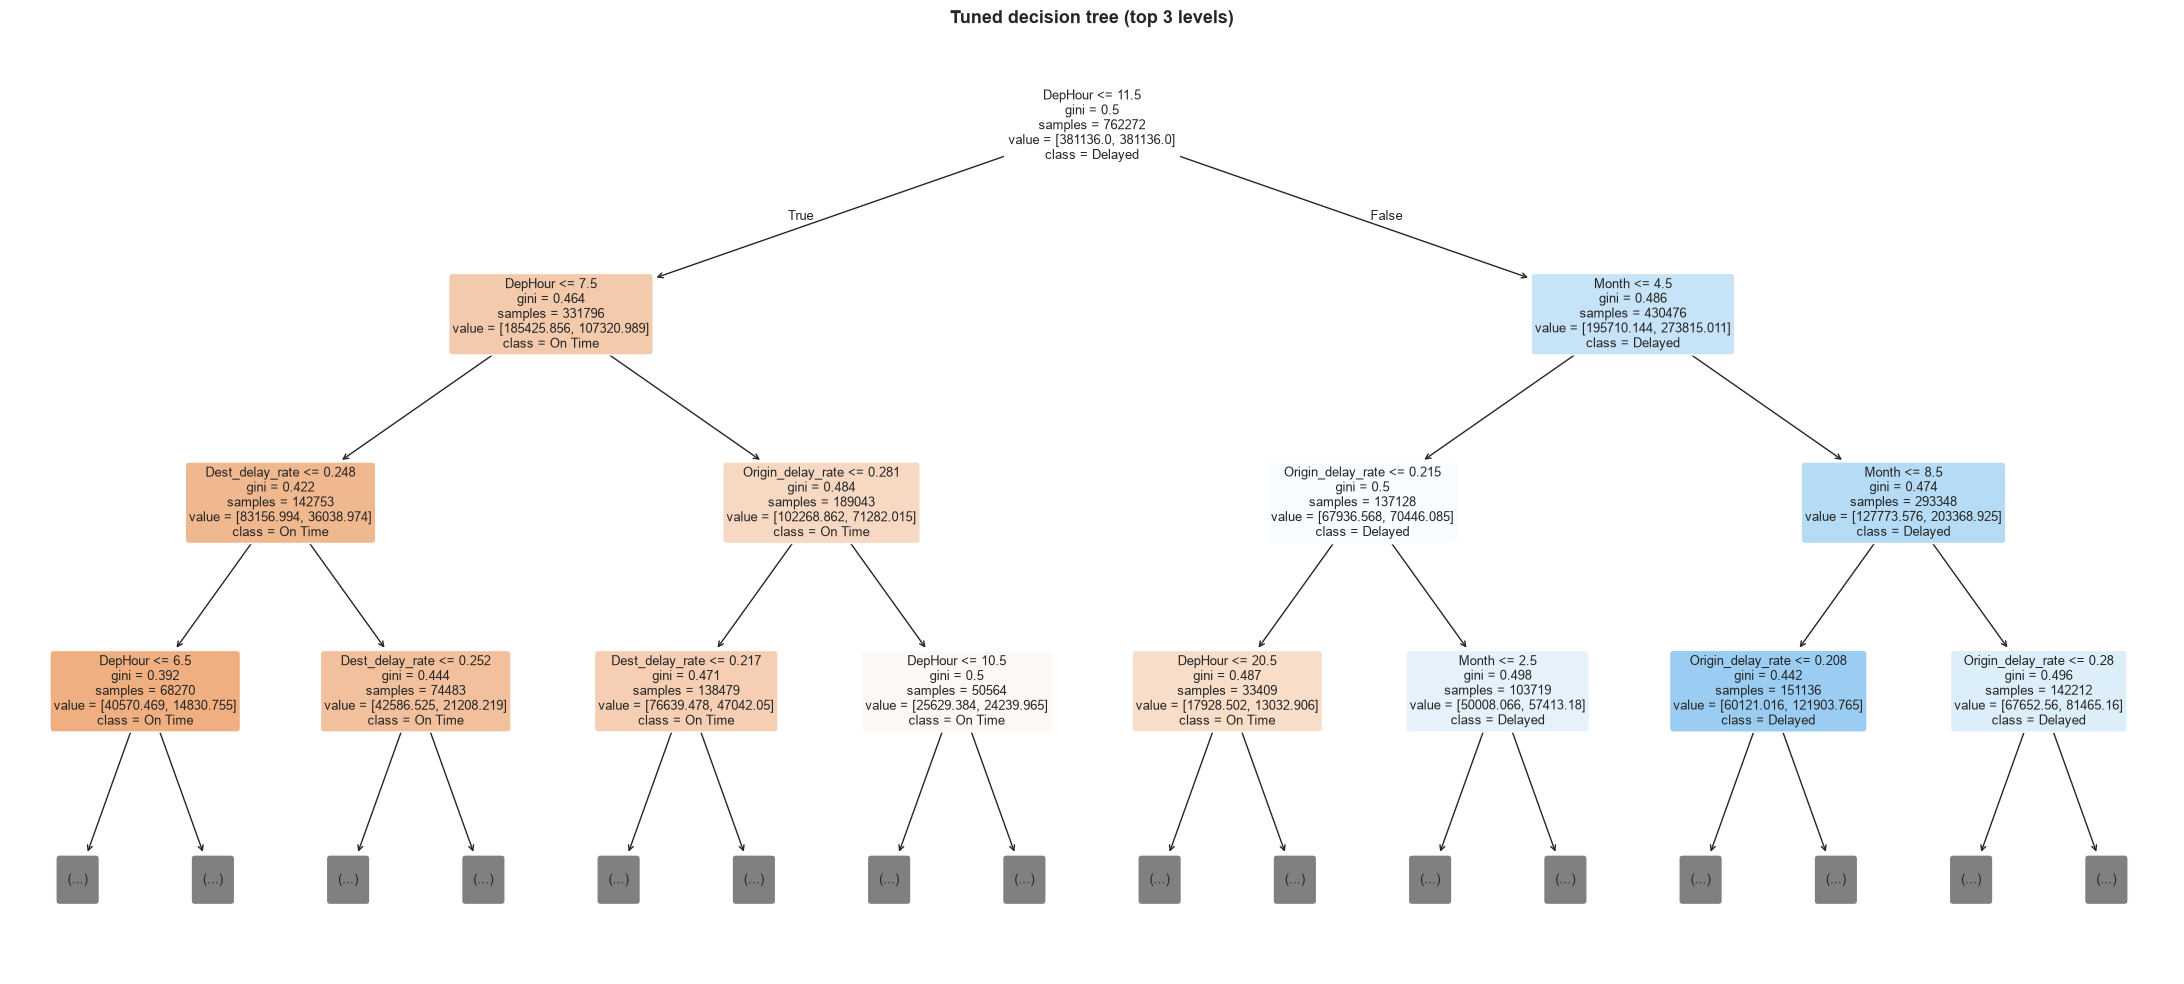

In [62]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(
    dtree_search.best_estimator_,
    max_depth=3,
    feature_names=FEATURES,
    class_names=["On Time", "Delayed"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
ax.set_title("Tuned decision tree (top 3 levels)")
plt.tight_layout()
plt.show()

**What we see:**

- **The default tree overfits badly.** With no limits it grows **49 levels deep with 213,300 leaves**, fewer than four training flights per leaf. It memorises the training data and does worse than logistic regression on the test set (F1 0.387, ROC-AUC 0.581).
- **Tuning fixes this.** The best settings are **`max_depth=15`** and **`min_samples_leaf=500`**, giving **F1 0.465** and **ROC-AUC 0.686**. CV ROC-AUC (0.683) and test ROC-AUC (0.686) are almost the same, so the tuned tree generalises well. Depth matters much more than leaf size: CV ROC-AUC rises from 0.642 at depth 3 to 0.683 at depth 15.
- **Capturing non-linear patterns helps.** The tuned tree beats logistic regression on both F1 (0.465 vs. 0.440) and ROC-AUC (0.686 vs. 0.647). A depth-3 tree scores about the same as logistic regression, so the gain comes from the deeper splits that a straight line can't express.
- **The top splits match the EDA.** The tree first splits on `DepHour` (before or after 11:30), the cascade effect from section 3.2. For later flights it then splits on `Month` at 4.5 and 8.5, which isolates the May–August summer peak, and then on the airport delay rates. **`PrevLegDelay` and `HasPrevLeg` don't appear in the top three levels.**
- **The new features barely change the result.** Compared with the 8-feature version (F1 0.464, ROC-AUC 0.685), the tree improves by only 0.001 on each metric, which is within noise.

A single tree is still unstable: a small change in the training data can give a very different tree. Combining many trees should help, which is what Random Forest does next.

### 5.4 Random Forest

Random Forest is an **ensemble method using bagging** (Module 3). Instead of one tree, it trains many trees in parallel, each on a random sample of the flights and a random subset of the features. The final prediction is a majority vote.

This reduces overfitting compared with a single tree, because the individual trees' mistakes tend to cancel out.

We use `class_weight="balanced"` and `n_jobs=-1` to train the trees in parallel.

#### Before tuning: default settings

The default forest has 100 trees with no depth limit. This is the most memory-hungry model in the notebook (about 3 GB).

In [63]:
rf_default = RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)

start = time.time()
rf_default.fit(X_train, y_train)
evaluate("RF (default)", rf_default, label="RF default", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.799     0.628     0.703    142923
     Delayed      0.320     0.525     0.398     47646

    accuracy                          0.602    190569
   macro avg      0.559     0.576     0.550    190569
weighted avg      0.679     0.602     0.627    190569

F1 (delayed): 0.398
ROC-AUC:      0.620
Training time: 18.6 s


#### After tuning: GridSearchCV

We tune three hyperparameters:

- **`n_estimators`:** how many trees to grow. More trees usually help but take longer.
- **`max_depth`:** depth limit per tree, as for the single decision tree.
- **`min_samples_leaf`:** minimum flights per leaf.

That is 2 × 3 × 2 = 12 combinations × 5 folds = 60 fits. This is the slowest grid in the notebook (typically 15–30 minutes).

In [64]:
rf_search = GridSearchCV(
    estimator=RandomForestClassifier(class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [10, 15, 20],
        "min_samples_leaf": [50, 100],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
rf_search.fit(X_train, y_train)
rf_time = time.time() - start

show_cv_results(rf_search)
evaluate("RF (tuned)", rf_search.best_estimator_, label="RF tuned", fit_time=rf_time)

Best params: {'max_depth': 20, 'min_samples_leaf': 50, 'n_estimators': 200}
Best CV ROC-AUC: 0.6970



,n_estimators,max_depth,min_samples_leaf,CV ROC-AUC,Std
9,200,20,50,0.6970,0.0010
8,100,20,50,0.6967,0.0009
5,200,15,50,0.6954,0.0011
4,100,15,50,0.6953,0.0011
11,200,20,100,0.6942,0.0010
10,100,20,100,0.6940,0.0009
7,200,15,100,0.6933,0.0011
6,100,15,100,0.6932,0.0011
1,200,10,50,0.6857,0.0011
0,100,10,50,0.6855,0.0011


              precision    recall  f1-score   support

     On Time      0.842     0.662     0.741    142923
     Delayed      0.382     0.628     0.475     47646

    accuracy                          0.654    190569
   macro avg      0.612     0.645     0.608    190569
weighted avg      0.727     0.654     0.675    190569

F1 (delayed): 0.475
ROC-AUC:      0.699
Training time: 1112.0 s


**What we see:**

- **The default forest overfits too.** Its trees have no depth limit, just like the default tree. Averaging 100 of them helps (ROC-AUC 0.620 vs. 0.581 for the default tree), but it is still worse than logistic regression (F1 0.398).
- **Tuning gives a clear gain.** The best settings are **`n_estimators=200`**, **`max_depth=20`** and **`min_samples_leaf=50`**, giving **F1 0.475** and **ROC-AUC 0.699**. Depth and leaf size are what matter: 200 trees score only 0.0003 higher than 100 in CV (0.6970 vs. 0.6967). The best values are at the edge of the grid, so slightly deeper trees might help a little.
- **Bagging helps, but only a little.** The tuned forest beats the tuned single tree on both F1 (0.475 vs. 0.465) and ROC-AUC (0.699 vs. 0.686). Averaging many trees smooths out the single tree's instability, but the gain is much smaller than the jump from logistic regression to trees.
- **It is by far the slowest model.** The grid search took **1,112 s (about 18.5 minutes)**, more than 50 times as long as the decision tree grid, for a gain of about 0.01 in F1 and ROC-AUC.
- **No real change from the new features.** The 8-feature forest scored F1 0.475 and ROC-AUC 0.698, so the previous-leg features add 0.001 ROC-AUC and nothing in F1.

Random Forest's trees are independent, so none of them learns from the others' mistakes. Boosting does exactly that, which is what XGBoost tries next.

### 5.5 XGBoost

XGBoost is an **ensemble method using boosting** (Module 3). Unlike Random Forest, where the trees are independent, XGBoost trains trees **one after another**: each new tree focuses on the flights the previous trees got wrong. It also adds regularisation to prevent overfitting.

We use `scale_pos_weight=3` (roughly the ratio of on-time to delayed flights, 75/25) instead of `class_weight`. It is XGBoost's name for the same idea.

#### Before tuning: default settings

In [65]:
xgb_default = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=3,
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

start = time.time()
xgb_default.fit(X_train, y_train)
evaluate("XGB (default)", xgb_default, label="XGB default", fit_time=time.time() - start)

              precision    recall  f1-score   support

     On Time      0.845     0.656     0.739    142923
     Delayed      0.382     0.637     0.478     47646

    accuracy                          0.652    190569
   macro avg      0.613     0.647     0.608    190569
weighted avg      0.729     0.652     0.673    190569

F1 (delayed): 0.478
ROC-AUC:      0.700
Training time: 1.0 s


#### After tuning: GridSearchCV

We tune three hyperparameters:

- **`n_estimators`:** number of boosting rounds (trees added one after another).
- **`max_depth`:** depth of each tree. Boosted trees are usually shallower than bagged ones, because each tree only needs to correct small errors.
- **`learning_rate`:** how much each new tree influences the prediction. Smaller values need more trees but often generalise better.

That is 2 × 3 × 2 = 12 combinations × 5 folds = 60 fits.

In [66]:
xgb_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=3,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    param_grid={
        "n_estimators": [100, 200],
        "max_depth": [3, 5, 7],
        "learning_rate": [0.01, 0.1],
    },
    scoring="roc_auc",
    cv=5,
    n_jobs=-1,
)

start = time.time()
xgb_search.fit(X_train, y_train)
xgb_time = time.time() - start

show_cv_results(xgb_search)
evaluate("XGB (tuned)", xgb_search.best_estimator_, label="XGB tuned", fit_time=xgb_time)

Best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200}
Best CV ROC-AUC: 0.6995



,n_estimators,max_depth,learning_rate,CV ROC-AUC,Std
11,200,7,0.10,0.6995,0.0012
10,100,7,0.10,0.6967,0.0012
9,200,5,0.10,0.6935,0.0011
8,100,5,0.10,0.6895,0.0013
5,200,7,0.01,0.6856,0.0010
7,200,3,0.10,0.6850,0.0012
6,100,3,0.10,0.6819,0.0012
4,100,7,0.01,0.6812,0.0009
3,200,5,0.01,0.6771,0.0010
2,100,5,0.01,0.6728,0.0009


              precision    recall  f1-score   support

     On Time      0.845     0.658     0.739    142923
     Delayed      0.383     0.637     0.478     47646

    accuracy                          0.652    190569
   macro avg      0.614     0.647     0.609    190569
weighted avg      0.729     0.652     0.674    190569

F1 (delayed): 0.478
ROC-AUC:      0.702
Training time: 65.1 s


**What we see:**

- **XGBoost is strong even with default settings.** Without any tuning it reaches **F1 0.478** and **ROC-AUC 0.700**, already slightly better than the tuned Random Forest, and it trains in **1 second**. This reflects its built-in regularisation: every tree is shrunk by the learning rate and penalised for large leaf weights, and the default trees are only 6 levels deep. So unlike the default tree and forest, it doesn't overfit out of the box.
- **Tuning adds very little.** The best settings are **`learning_rate=0.1`**, **`max_depth=7`** and **`n_estimators=200`**, giving **F1 0.478** and **ROC-AUC 0.702**. F1 doesn't move at all and ROC-AUC rises by 0.002.
- **`learning_rate` and `n_estimators` work together.** A smaller learning rate means each tree makes a smaller correction, so more trees are needed for the same result. With `learning_rate=0.01`, even 200 trees are not enough: the best CV ROC-AUC is 0.686, below a depth-5 model with only 100 trees at 0.1 (0.690). The best combination is the largest one in the grid, so more rounds might still help slightly.
- **XGBoost is the best model, but only just.** It beats the tuned Random Forest on F1 (0.478 vs. 0.475) and ROC-AUC (0.702 vs. 0.699), and its whole grid search takes 65 s instead of 1,112 s. That makes it the most practical choice too.
- **Identical to the 8-feature version.** The old tuned XGBoost also scored F1 0.478 and ROC-AUC 0.702, so the previous-leg features add nothing measurable here.

### 5.6 Model Comparison

Now we compare all models side by side. The table includes both the default and tuned version of each model, so we can see what tuning added. For the plots we use the tuned version of each model (the DummyClassifier baseline has nothing to tune).

#### Summary table

One row per model. For the tuned models, the training time includes the whole grid search.

In [67]:
MODEL_ORDER = [
    "Dummy",
    "LogReg (default)", "LogReg (tuned)",
    "DTree (default)", "DTree (tuned)",
    "RF (default)", "RF (tuned)",
    "XGB (default)", "XGB (tuned)",
]

summary = pd.DataFrame([
    {
        "Model": name,
        "F1 (delayed)": results[name]["f1"],
        "ROC-AUC": results[name]["auc"],
        "Training time (s)": results[name]["fit_time"],
    }
    for name in MODEL_ORDER
])
display(summary.round({"F1 (delayed)": 3, "ROC-AUC": 3, "Training time (s)": 1}))

,Model,F1 (delayed),ROC-AUC,Training time (s)
0,Dummy,0.000,0.500,0.0
1,LogReg (default),0.440,0.647,2.6
2,LogReg (tuned),0.440,0.647,31.6
3,DTree (default),0.387,0.581,2.2
4,DTree (tuned),0.465,0.686,20.7
5,RF (default),0.398,0.620,18.6
6,RF (tuned),0.475,0.699,1112.0
7,XGB (default),0.478,0.700,1.0
8,XGB (tuned),0.478,0.702,65.1


#### F1 for the delayed class

How well each model balances catching delays against raising false alarms, sorted from best to worst.

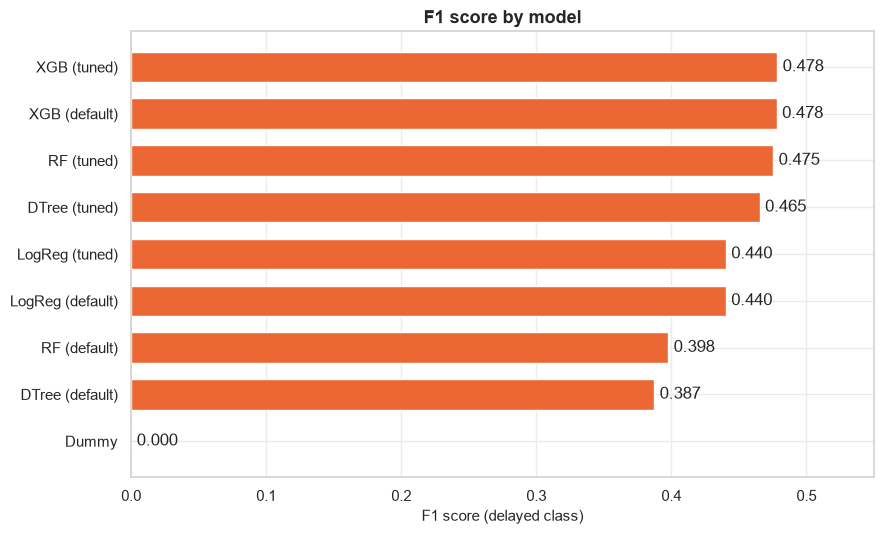

In [68]:
f1_sorted = summary.sort_values("F1 (delayed)")

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(f1_sorted["Model"], f1_sorted["F1 (delayed)"], color=COLOR_DELAYED, height=0.65)
ax.bar_label(bars, fmt="%.3f", padding=4)

ax.set_xlim(0, f1_sorted["F1 (delayed)"].max() * 1.15)
ax.set_xlabel("F1 score (delayed class)")
ax.set_title("F1 score by model")
plt.tight_layout()
plt.show()

#### ROC curves

A ROC curve shows how each model trades off catching delays (true positive rate) against false alarms (false positive rate) across **all** possible thresholds, not just 0.5. The closer a curve gets to the top-left corner, the better. The dashed diagonal is random guessing.

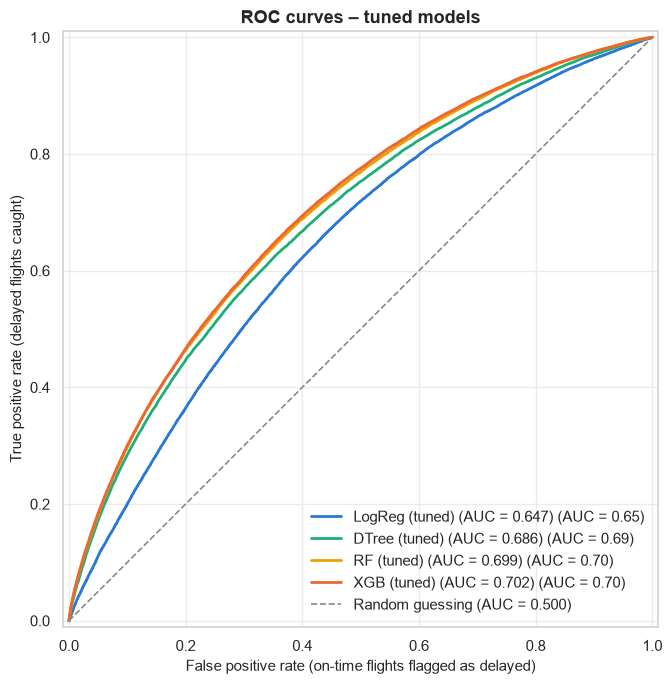

In [69]:
TUNED_MODELS = ["LogReg (tuned)", "DTree (tuned)", "RF (tuned)", "XGB (tuned)"]
MODEL_COLORS = {
    "LogReg (tuned)": COLOR_ONTIME,
    "DTree (tuned)": "#1baf7a",
    "RF (tuned)": "#eda100",
    "XGB (tuned)": COLOR_DELAYED,
}

fig, ax = plt.subplots(figsize=(7.5, 7))
for name in TUNED_MODELS:
    RocCurveDisplay.from_predictions(
        y_test, results[name]["y_proba"], ax=ax,
        name=f"{name} (AUC = {results[name]['auc']:.3f})",
        curve_kwargs={"color": MODEL_COLORS[name], "linewidth": 2},
    )
ax.plot([0, 1], [0, 1], color=COLOR_REF, linestyle="--", linewidth=1.2, label="Random guessing (AUC = 0.500)")

ax.set_xlabel("False positive rate (on-time flights flagged as delayed)")
ax.set_ylabel("True positive rate (delayed flights caught)")
ax.set_title("ROC curves – tuned models")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

#### Confusion matrices

The confusion matrices show the actual counts behind the metrics, at the default threshold of 0.5:

- **Top left:** on-time flights correctly predicted as on time.
- **Top right:** false alarms (on time, but predicted delayed).
- **Bottom left:** missed delays (delayed, but predicted on time).
- **Bottom right:** delays caught.

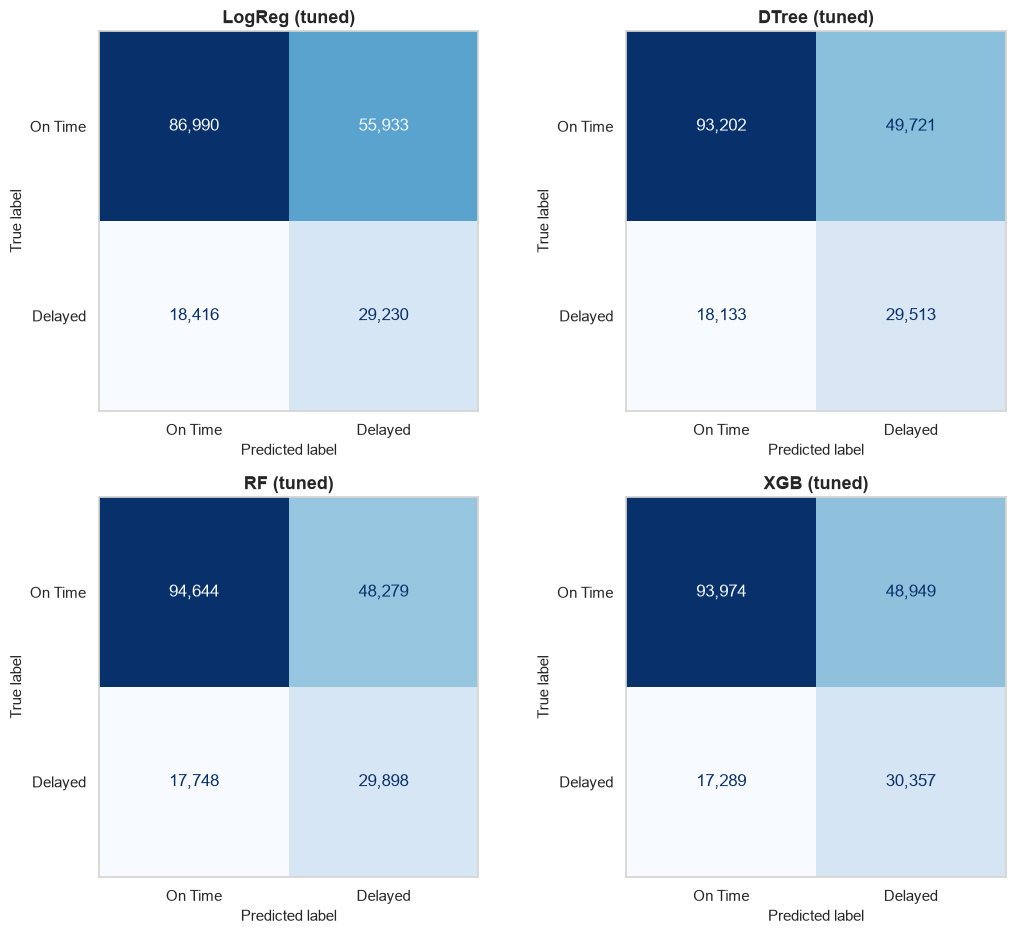

In [70]:
fig, axes = plt.subplots(2, 2, figsize=(11, 9.5))

for ax, name in zip(axes.flat, TUNED_MODELS):
    ConfusionMatrixDisplay.from_predictions(
        y_test, results[name]["y_pred"], display_labels=["On Time", "Delayed"],
        cmap="Blues", values_format=",", colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.grid(False)

plt.tight_layout()
plt.show()

#### Conclusion

- **Each step up in model complexity helped, but the gains shrink.** F1 (delayed) and ROC-AUC for the tuned models:
  - Dummy: 0.000 / 0.500
  - Logistic Regression: 0.440 / 0.647
  - Decision Tree: 0.465 / 0.686
  - Random Forest: 0.475 / 0.699
  - XGBoost: **0.478 / 0.702**
- **XGBoost wins on both F1 and ROC-AUC.** It is also fast: the default model trains in 1 second and already beats the tuned Random Forest.
- **The problem is non-linear.** The biggest single jump is from logistic regression to a decision tree (+0.039 ROC-AUC). This matches the EDA: delays depend on ranges of `DepHour` and `Month` (the evening and summer peaks), not on straight-line effects. The tree's top splits are exactly these features.
- **Ensembles add a smaller extra gain.** Bagging (Random Forest) and boosting (XGBoost) add about another 0.015 ROC-AUC over the best single tree. Most of the benefit comes from capturing non-linearity at all; combining trees only refines it.
- **Tuning matters most for models that overfit.** It lifted the decision tree's ROC-AUC from 0.581 to 0.686 and the Random Forest's from 0.620 to 0.699, because their defaults grow without limits. For logistic regression and XGBoost, which are already regularised, it changed almost nothing.

**The impact of `PrevLegDelay`:** The previous-leg features were meant to capture the cascade effect, the biggest single cause of delays (late aircraft, 41% of delay minutes, section 3.6). In practice they **barely moved the results**: the best ROC-AUC is **0.702**, exactly the same as without them, and the other models improve by 0.001–0.002 at most. The reason is the T-2 rule. AA's turnarounds are mostly shorter than 2 hours, so for most flights the previous leg is still in the air at prediction time and can't be used. Only **8% of flights** have a qualifying previous leg (section 4.1b). Those aircraft then sit on the ground for 2+ hours, which is enough buffer to absorb most of the incoming delay: their delay rate is only slightly higher (26.7% vs. 24.9%). The cascade effect is real, but at T-2 it is mostly visible through `DepHour`, which the models already use.

**Limitations:** A ROC-AUC of 0.70 is clearly better than guessing, but still modest. At the default threshold the best model catches about 64% of delays, but only about 38% of its delay warnings are correct, so most alerts are false alarms. The biggest missing piece is **weather**: the dataset has no weather information, even though bad weather drives many of the NAS and weather delays (section 3.6). Schedule-based features can only tell the model which flights are *usually* risky, not which ones are at risk *today*.

**What could still improve it:** Adding weather forecasts for the origin and destination airports, which are available hours before departure, would most likely give the biggest improvement.

## 6. Interpretability

We now look at **which features the best models rely on**. A good score is not enough for the operations team: they also need to understand *why* the model flags a flight. If `DepHour` drives most predictions, for example, they know to focus standby crews and spare aircraft on evening departures.

We use two methods:

- **Tree-based importance (MDI):** built into the tree models, and quick to compute.
- **Permutation importance:** measured on the test set, and works for any model.

### 6.1 Tree-based feature importance (MDI)

**MDI** (Mean Decrease in Impurity) measures how much each feature improves the splits it is used in. Every time a tree splits on a feature, the node gets purer (lower Gini). MDI adds up these improvements over all splits and all trees. Features that are used in many splits, especially high up in the trees where many flights pass through, get higher scores. The scores sum to 1, so each bar is the feature's share of the total.

For XGBoost the same idea is measured as **gain**: how much each split on the feature reduces the model's loss.

**Caveat:** MDI is calculated on the training data, and it can be biased. In Random Forest it tends to **overweight continuous features** with many possible split points (like `Distance` or the airport delay rates). XGBoost's gain is averaged per split, so a feature used in only a **few splits with a large gain each** can look important even if it does little overall. That is why we check both with permutation importance in 6.2.

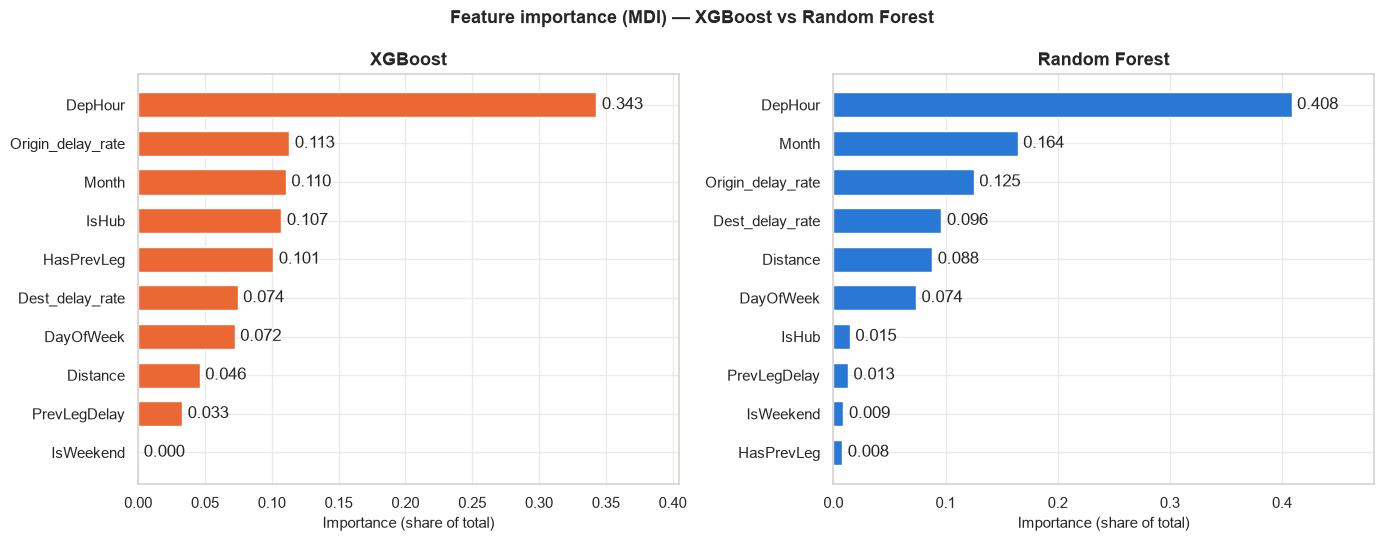

In [ ]:
mdi = pd.DataFrame({
    "XGBoost": results["XGB (tuned)"]["model"].feature_importances_,
    "Random Forest": results["RF (tuned)"]["model"].feature_importances_,
}, index=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, (name, color) in zip(axes, [("XGBoost", COLOR_DELAYED), ("Random Forest", COLOR_ONTIME)]):
    imp_sorted = mdi[name].sort_values()
    bars = ax.barh(imp_sorted.index, imp_sorted.values, color=color, height=0.65)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set_xlim(0, imp_sorted.max() * 1.18)
    ax.set_xlabel("Importance (share of total)")
    ax.set_title(name)

fig.suptitle("Feature importance (MDI) — XGBoost vs Random Forest", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**What we see:**

- **`DepHour` dominates in both models.** It accounts for **0.343** of XGBoost's importance and **0.408** of Random Forest's, more than a third of the total. This is the cascade effect from section 3.2: the delay rate climbs from about 11% for early-morning departures to about 37% in the evening.
- **`Month` and the airport delay rates come next.** In Random Forest: `Month` 0.164, `Origin_delay_rate` 0.125, `Dest_delay_rate` 0.096. In XGBoost: `Origin_delay_rate` 0.113, `Month` 0.110. These match the summer peak (section 3.3) and the differences between airports (section 3.5).
- **The two models disagree on the binary features.** XGBoost ranks `IsHub` (0.107) and `HasPrevLeg` (0.101) fourth and fifth, while Random Forest gives them only 0.015 and 0.008. This is the bias from the caveat above: a 0/1 feature has a single possible split, and if XGBoost uses it in a few high-gain splits, its *average* gain looks large. Random Forest leans the other way and gives more weight to continuous features such as `Distance` (0.088 vs. 0.046 in XGBoost).
- **`IsWeekend` contributes nothing to XGBoost (0.000).** It is redundant: `DayOfWeek` already contains the same information (days 6 and 7), so the trees split on that instead.

Because the two MDI rankings disagree in the middle, we check them against permutation importance, which measures what actually helps on the test set.

### 6.2 Permutation importance

**Permutation importance** asks a simple question: *how much worse does the model get if we scramble one feature?* We shuffle the values of one feature in the test set, so it no longer carries any information, and measure how much the ROC-AUC drops. If it drops a lot, the model relies on that feature. If it barely changes, the feature doesn't matter.

This has two advantages over MDI:

- **Model-agnostic:** it only needs predictions, so it works the same way for any model.
- **Measured on the test set:** it shows what actually helps on new flights, and it doesn't favour continuous features.

We run it on the **tuned XGBoost** model, our best model, with `n_repeats=10`: each feature is shuffled 10 times and the drops are averaged.

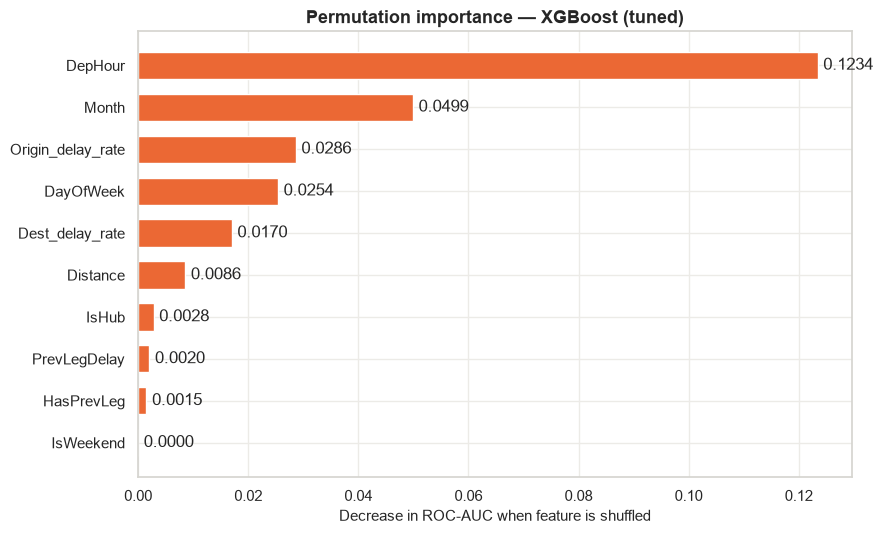

In [ ]:
perm_result = permutation_importance(
    results["XGB (tuned)"]["model"], X_test, y_test,
    scoring="roc_auc", n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1
)

perm_importances = pd.Series(perm_result.importances_mean, index=FEATURES)

fig, ax = plt.subplots(figsize=(9, 5.5))
perm_sorted = perm_importances.sort_values()
bars = ax.barh(perm_sorted.index, perm_sorted.values, color=COLOR_DELAYED, height=0.65)
ax.bar_label(bars, fmt="%.4f", padding=4)
ax.set_xlabel("Decrease in ROC-AUC when feature is shuffled")
ax.set_title("Permutation importance — XGBoost (tuned)")
plt.tight_layout()
plt.show()

**What we see:**

- **`DepHour` is by far the most important feature.** Shuffling it drops the ROC-AUC by **0.123**, from 0.702 to about 0.58, and more than twice as much as any other feature. Without the departure hour, the model loses most of its skill.
- **`Month` comes second (0.050), followed by `Origin_delay_rate` (0.029), `DayOfWeek` (0.025) and `Dest_delay_rate` (0.017).** This is the same top group as in MDI: *when* the flight departs (time of day, season, weekday) and *where* it departs from and flies to.
- **The binary features matter very little on new flights.** `IsHub` drops the ROC-AUC by only 0.003 and `HasPrevLeg` by 0.0015, far below their high XGBoost gain ranking. So MDI overstated them. `IsHub` mostly repeats what `Origin_delay_rate` already says, because each hub has its own delay rate.
- **The previous-leg features are near the bottom.** `PrevLegDelay` (0.0020) and `HasPrevLeg` (0.0015) together cost less than 0.004 ROC-AUC, which confirms the finding in section 5.6 that they add almost nothing.
- **`IsWeekend` has no effect at all (0.0000)** and could be dropped without any loss. `Distance` is also small (0.009).

The standard deviations over the 10 repeats are all 0.001 or less, so this ranking is stable.

### 6.3 Interpretation summary

- **When a flight departs matters most.** `DepHour` is the top feature in both methods: 0.343–0.408 of MDI and a 0.123 drop in ROC-AUC when shuffled. This is the cascade effect from section 3.2, where delays build up through the day. For the operations team, the clearest lesson is to focus buffers, standby crews and spare aircraft on **afternoon and evening departures**.
- **Season and airport come next.** `Month` (the summer peak, section 3.3) and the airport delay rates (section 3.5, where DFW is the worst of the 10 busiest airports at 33%) make up most of the remaining signal. `DayOfWeek` adds a smaller weekly pattern.
- **Several features are redundant.** `IsWeekend` adds nothing beyond `DayOfWeek`, and `IsHub` adds little beyond `Origin_delay_rate`. `Distance` is weak, as the EDA suggested (flat delay rates up to 1,500 miles).
- **The previous-leg features rank near the bottom.** This confirms the conclusion in section 5.6. Late aircraft is the biggest cause of delays (41%, section 3.6), but under the T-2 rule the previous leg is usually still in the air, so the cascade effect reaches the model mainly through `DepHour`.
- **Surprise: the two methods disagree on binary features.** XGBoost's gain-based importance put `IsHub` and `HasPrevLeg` in its top five, but permutation importance shows they barely matter on the test set. Built-in importance scores should be checked with a test-set method before acting on them.

Overall, the model is mainly a **"when and where" model**: it recognises flights that are *usually* risky from their schedule and airports. It has no information about conditions on the day, which is why weather data remains the most promising next step.

## 7. Fairness

The operations team will use the model at **every airport AA flies from**, not just the big ones. If the model catches delays much better at the hubs, which each have far more flights to learn from than any smaller airport, those airports get worse service: fewer delays flagged in time, so fewer chances to rebook passengers or reposition crews.

Hub flights are also operationally different: more connections, tighter turnarounds and more congestion. So it is a real question whether one model works equally well for both.

We therefore check whether the tuned XGBoost model treats **hub** flights (departing from DFW, CLT, MIA, ORD or PHX) and **non-hub** flights equally, using `IsHub` as the **sensitive feature**.

### 7.1 Disparity analysis

We measure three metrics separately for each group, using fairlearn's `MetricFrame`:

- **True Positive Rate (TPR):** what share of the actual delays does the model catch? This is recall for the delayed class.
- **False Positive Rate (FPR):** what share of the on-time flights does it wrongly flag as delayed?
- **Selection rate:** what share of all flights does it predict as delayed?

A fair model should have **similar rates for both groups**. The *difference* between the groups is the disparity.

In [ ]:
sensitive_labels = X_test["IsHub"].map({1: "Hub", 0: "Non-hub"})

fairness_metrics = {
    "True Positive Rate": true_positive_rate,
    "False Positive Rate": false_positive_rate,
    "Selection Rate": selection_rate,
}

mf = MetricFrame(
    metrics=fairness_metrics,
    y_true=y_test,
    y_pred=results["XGB (tuned)"]["y_pred"],
    sensitive_features=sensitive_labels,
)

print("Metrics by group:")
print(mf.by_group.round(3))
print(f"\nOverall:")
print(mf.overall.round(3))
print(f"\nDisparity (difference between groups):")
print(mf.difference().round(3))

Metrics by group:
         True Positive Rate  False Positive Rate  Selection Rate
IsHub                                                           
Hub                   0.710                0.432           0.510
Non-hub               0.556                0.269           0.333

Overall:
True Positive Rate     0.637
False Positive Rate    0.342
Selection Rate         0.416
dtype: float64

Disparity (difference between groups):
True Positive Rate     0.154
False Positive Rate    0.163
Selection Rate         0.177
dtype: float64


**What we see:**

- **There is a clear disparity.** The model catches **71.0% of delays at hubs** but only **55.6% at non-hub airports**, a gap of **0.154** in TPR. In other words, non-hub airports miss almost half of their delays (44%), compared with 29% at the hubs.
- **Hub flights also get more false alarms.** The FPR is 0.432 at hubs vs. 0.269 elsewhere (gap 0.163), and the model flags **51%** of hub flights as delayed vs. **33%** of non-hub flights.
- **TPR and FPR are both higher at hubs, by about the same amount.** That pattern means the model doesn't *see* hub delays better. It simply gives hub flights **higher risk scores** on average, so more of them cross the single 0.5 threshold, whether they end up delayed or not. That makes sense: hubs really are more delay-prone (section 3.5: DFW 33%, with ORD and MIA close behind), and both `IsHub` and `Origin_delay_rate` push their scores up.

So the problem is the **shared threshold**, not the model's ranking. The same cut-off is effectively stricter for non-hub flights. This is exactly what a group-specific threshold can fix, which we try next.

### 7.2 Threshold optimization

fairlearn's `ThresholdOptimizer` is a **post-processing** method: it does not retrain the model. It takes the model's predicted delay probabilities and picks a **separate classification threshold for each group**, instead of the same 0.5 for everyone.

We use the **equalized odds** constraint: the thresholds are chosen so that both the TPR and the FPR are (as close as possible to) equal across hub and non-hub flights. Within that constraint, it picks the thresholds that score best on an **objective**.

**Choice of objective.** The default objective is plain **accuracy**. With 75% on-time flights, the most accurate thresholds simply flag very few flights. We tried this: the thresholds jump to about 0.72–0.77, the TPR falls to about 0.13 for *both* groups, and F1 (delayed) drops from 0.478 to 0.213. That is "fair", but only because the model barely catches any delays anywhere, and the F1 drop mostly comes from changing the objective, not from fairness. We therefore use **`balanced_accuracy_score`**, which weighs both classes equally. This matches the `class_weight="balanced"` setup we used for every model, so the before and after results can be compared fairly.

To meet the constraint exactly, it sometimes has to mix two thresholds at random for a group, so we fix `random_state` to make the predictions reproducible.

In [ ]:
class Float64Proba(ClassifierMixin, BaseEstimator):
    """Wrap a fitted model so predict_proba returns float64.

    XGBoost returns float32 probabilities, which fairlearn's ThresholdOptimizer
    can't handle with pandas 3. The probabilities themselves are unchanged.
    """

    def __init__(self, model):
        self.model = model

    def fit(self, X, y):
        return self  # the wrapped model is already fitted

    def __sklearn_is_fitted__(self):
        return True

    def predict_proba(self, X):
        return self.model.predict_proba(X).astype(np.float64)


thresh_opt = ThresholdOptimizer(
    estimator=Float64Proba(results["XGB (tuned)"]["model"]),
    constraints="equalized_odds",
    objective="balanced_accuracy_score",
    prefit=True,
    predict_method="predict_proba",
)

thresh_opt.fit(X_train, y_train, sensitive_features=X_train["IsHub"])

y_fair_pred = thresh_opt.predict(X_test, sensitive_features=X_test["IsHub"], random_state=RANDOM_STATE)

mf_fair = MetricFrame(
    metrics=fairness_metrics,
    y_true=y_test,
    y_pred=y_fair_pred,
    sensitive_features=sensitive_labels,
)

print("After ThresholdOptimizer — Metrics by group:")
print(mf_fair.by_group.round(3))
print(f"\nDisparity after optimization:")
print(mf_fair.difference().round(3))

f1_before = f1_score(y_test, results["XGB (tuned)"]["y_pred"])
f1_after = f1_score(y_test, y_fair_pred)
print(f"\nF1 (delayed) before: {f1_before:.3f}")
print(f"F1 (delayed) after:  {f1_after:.3f}")

After ThresholdOptimizer — Metrics by group:
         True Positive Rate  False Positive Rate  Selection Rate
IsHub                                                           
Hub                   0.648                0.369           0.448
Non-hub               0.650                0.364           0.428

Disparity after optimization:
True Positive Rate     0.002
False Positive Rate    0.005
Selection Rate         0.020
dtype: float64

F1 (delayed) before: 0.478
F1 (delayed) after:  0.472


**What we see:**

- **The disparity is practically gone.** After threshold optimization, the TPR is **0.648 at hubs vs. 0.650 at non-hubs** (gap 0.002, down from 0.154), and the FPR is 0.369 vs. 0.364 (gap 0.005, down from 0.163).
- **Both groups move towards the middle.** For non-hub flights the threshold is effectively lowered, so they catch far more delays (TPR 0.556 → 0.650) at the cost of more false alarms (FPR 0.269 → 0.364). For hub flights it is raised: fewer delays caught (0.710 → 0.648) but also fewer false alarms (0.432 → 0.369).
- **The selection rates line up too.** The share of flights flagged is now 44.8% vs. 42.8% (gap 0.020, down from 0.177), even though equalized odds doesn't target this directly.
- **The cost in performance is small.** F1 (delayed) drops only from **0.478 to 0.472**. No retraining is needed: the same XGBoost model is used, with two different cut-offs.

One caveat: the thresholds were chosen using the model's predictions on the *training* set, which are slightly optimistic. Ideally we would use a separate validation set. But the gaps also close on the test set, so the thresholds carry over well to new flights.

### 7.3 Visualization

The true positive rate by group, before and after `ThresholdOptimizer`.

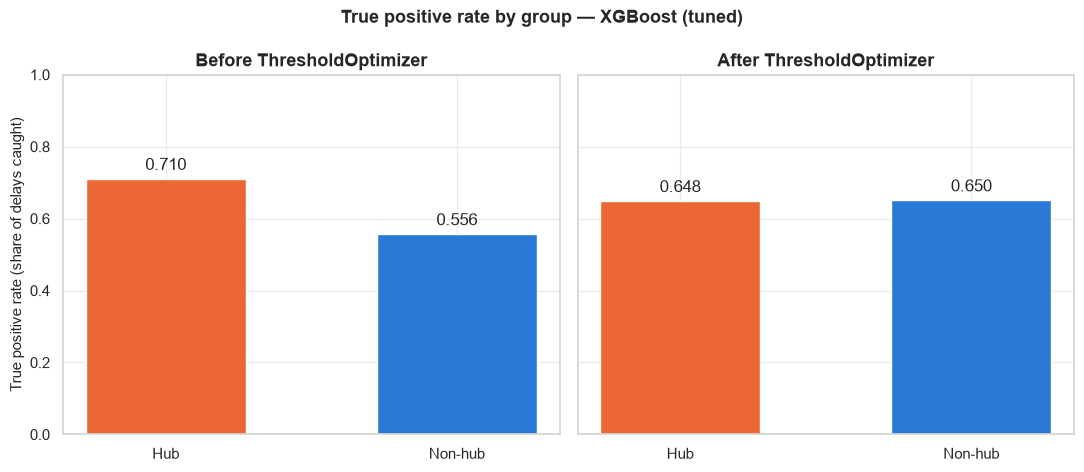

In [ ]:
GROUPS = ["Hub", "Non-hub"]
GROUP_COLORS = [COLOR_DELAYED, COLOR_ONTIME]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, (title, frame) in zip(axes, [("Before ThresholdOptimizer", mf), ("After ThresholdOptimizer", mf_fair)]):
    tpr = frame.by_group["True Positive Rate"].reindex(GROUPS)
    bars = ax.bar(GROUPS, tpr.values, color=GROUP_COLORS, width=0.55)
    ax.bar_label(bars, fmt="%.3f", padding=4)
    ax.set_title(title)

axes[0].set_ylabel("True positive rate (share of delays caught)")
axes[0].set_ylim(0, 1)
fig.suptitle("True positive rate by group — XGBoost (tuned)", fontweight="bold", fontsize=13)
plt.tight_layout()
plt.show()

**What we see:** Before optimization, the hub bar is clearly taller than the non-hub bar (0.710 vs. 0.556), so hub delays are caught far more often. After optimization, the two bars are the same height (0.648 vs. 0.650). The non-hub bar rises much more than the hub bar falls, so overall the model now catches delays **consistently across the whole network**.

### 7.4 Fairness summary

- **There was a meaningful disparity.** With a single threshold, the tuned XGBoost model caught 71.0% of delays at hubs but only 55.6% at non-hub airports (a 0.154 gap in TPR), and it raised more false alarms at hubs (0.432 vs. 0.269 FPR).
- **The cause is the threshold, not the model's skill.** Both TPR and FPR are higher at hubs, by about the same amount. The model gives hub flights higher risk scores because hubs really are more delay-prone (section 3.5), so one shared cut-off flags far more of them.
- **`ThresholdOptimizer` closed the gap almost completely.** With equalized odds and a separate threshold per group, both groups end up with a TPR of about 0.65 and an FPR of about 0.37 (gaps of 0.002 and 0.005).
- **The cost in F1 is small.** F1 (delayed) drops from 0.478 to 0.472, and the model itself doesn't change.
- **The objective matters.** With fairlearn's default accuracy objective, the gap also closes, but only by flagging almost nothing: TPR falls to about 0.13 and F1 to 0.213. Fairness tools need to be set up to match what the business actually wants from the model.

**Is the trade-off acceptable for the operations team?** In our view, yes. For a cost of 0.006 in F1, smaller airports go from missing 44% of their delays to missing 35%, and every station gets the same level of service from the tool. In practice it is also simple: two thresholds instead of one. Hubs do give up some caught delays (71.0% → 64.8%), though, and a missed delay at a hub can affect more connecting passengers. So whether *equal* detection rates are the right goal, or whether hubs should keep a slightly lower threshold, is ultimately a **business decision** for AA, not a purely technical one. The analysis shows how big the trade-off is, so that decision can be made on an informed basis.